# <font color="lightblue">Adult Income Classification: Comparative Machine Learning Model Evaluation</font>
**University of Santo Tomas | College of Science** **Course:** DSA4155: Artificial Intelligence  
**Dataset:** Adult Income (Census 1994)  

---
* **Submitted by:** OYALES, Cherelle Valkyrie R.

## <font color="lightblue"> Summary </font>
Using the Adult Income dataset, we aim to find the most suitable model to predict the individuals with high income (>50k) or not (<50k). It is discovered during exploratory data analysis that majority class is those without high income, creating a class imbalance that might cause bias in predicting the majority class better than the minority class. Before the model training started, the features used were decided by using the Decision tree's feature importance ranking and splitted accordingly by 80/20. LPM, Logistic Regression, K-Nearest Neighbors, Decision Trees, Bagging, Random Forest, Adaptive Boosting, and Gradient Boosting were the models trained and tested to determine the most suited model for our classification problem. After comparison, Gradient Boosting produced the best accuracy and F1-score, balancing the error rates better than the other models.

In [50]:
# IMPORT LIBRARIES
# Core Data & Math
import random
import time
import warnings
import numpy as np
import pandas as pd
from scipy import stats
from scipy.spatial.distance import pdist, squareform
from scipy.stats import entropy

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical Modeling
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.genmod.families import Binomial
from statsmodels.stats.outliers_influence import variance_inflation_factor, summary_table

# Scikit-Learn: Preprocessing, Datasets & Selection
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV, validation_curve
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.datasets import fetch_openml
from sklearn.inspection import permutation_importance

# Scikit-Learn: Models
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV

# Scikit-Learn: Metrics & Evaluation
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, 
    confusion_matrix, classification_report, ConfusionMatrixDisplay,
    mean_squared_error, mean_absolute_error, r2_score,
    roc_auc_score, roc_curve, precision_recall_curve
)
# 7. Settings
import warnings
warnings.filterwarnings('ignore')

# Setting the global random seed for reproducibility
# Set random seed for reproducibility
np.random.seed(42)

# Set plotting style
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

print("Libraries loaded.")

Libraries loaded.


## 1. Data Preparation and Exploratory Data Analysis

### 1A. Data Loading and Preprocessing

In [53]:
# Fetching the dataset from OpenML
adult = fetch_openml("adult", as_frame=True, version=2)
orig_df = adult.frame
df = orig_df.copy()
print ("Dataset loaded.")
orig_df.info()

Dataset loaded.
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  class           48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


In [54]:
# Finding Missing Values
print("Values with '?':")
print("="*20)
print((orig_df=="?").sum(), "\n")

print("Values with 'NaN':")
print("="*20)
print(orig_df.isnull().sum())

Values with '?':
age               0
workclass         0
fnlwgt            0
education         0
education-num     0
marital-status    0
occupation        0
relationship      0
race              0
sex               0
capital-gain      0
capital-loss      0
hours-per-week    0
native-country    0
class             0
dtype: int64 

Values with 'NaN':
age                  0
workclass         2799
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        2809
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     857
class                0
dtype: int64


In [55]:
# Drop the rows with missing values
df = df.dropna()

print(f"Original shape: {orig_df.shape}")
print(f"Cleaned shape: {df.shape}")
print(f"Rows removed: {len(orig_df) - len(df)}")

Original shape: (48842, 15)
Cleaned shape: (45222, 15)
Rows removed: 3620


##### Explanation
The rows with missing values were dropped because it only makes up 7% of the original dataset. Hence, we still have enough observations left after the drop.

In [57]:
# Mapping 'Education' and 'Marital Status' to specific categories.
edu_map = {
    # Preschool & Gradeschool
    'Preschool': 'Gradeschool', '1st-4th': 'Gradeschool', 
    '5th-6th': 'Gradeschool', '7th-8th': 'Gradeschool',
    
    # High School (Non-grads and Grads)
    '9th': 'High School', '10th': 'High School', '11th': 'High School', 
    '12th': 'High School', 'HS-grad': 'High School',
    
    # College (Associates / Some College)
    'Some-college': 'Some College/Assoc', 'Assoc-voc': 'Some College/Assoc', 
    'Assoc-acdm': 'Some College/Assoc',
    
    # Bachelors
    'Bachelors': 'Bachelors',
    
    # Advanced Degrees
    'Masters': 'Masters/Doctorate', 'Prof-school': 'Masters/Doctorate', 'Doctorate': 'Masters/Doctorate'
}

df['education'] = df['education'].map(edu_map)

marital_map = {
    # The Married Group (Current)
    'Married-civ-spouse': 'Married', 
    'Married-AF-spouse': 'Married', 
    'Married-spouse-absent': 'Married',
    
    # The Never-Married Group
    'Never-married': 'Never-Married',
    
    # The Previously Married Group (Dissolved)
    'Divorced': 'Previously-Married', 
    'Separated': 'Previously-Married', 
    'Widowed': 'Previously-Married'
}

df['marital-status'] = df['marital-status'].map(marital_map)

##### Explanation
Some values in the variables were found to be repetitive and can be merged together with other values under a similar category. Hence, these values were mapped accordingly.

In [59]:
# Create the target variable: high_income (1 if >50K, else 0)
df['high_income'] = (df['class'] == '>50K').astype(int)
df = df.drop('class', axis=1)

In [60]:
# Convert "education" categorical variables to dummy variables
df['education'] = df['education'].replace(np.nan, "Unknown")

df = pd.get_dummies(df, columns=['education'], drop_first=True, prefix='education')

In [61]:
# Convert "workclass" categorical variables to dummy variables
df['workclass'] = df['workclass'].replace(np.nan, "Unknown")

df = pd.get_dummies(df, columns=['workclass'], drop_first=True, prefix='workclass')

In [62]:
# Convert "marital.status" categorical variables to dummy variables
df['marital-status'] = df['marital-status'].replace(np.nan, "Unknown")

df = pd.get_dummies(df, columns=['marital-status'], drop_first=True, prefix='marital-status')

In [63]:
# Convert "occupation" categorical variables to dummy variables
df['occupation'] = df['occupation'].replace(np.nan, "Unknown")

df = pd.get_dummies(df, columns=['occupation'], drop_first=True, prefix='occupation')

In [64]:
# Convert "relationship" categorical variables to dummy variables
df['relationship'] = df['relationship'].replace(np.nan, "Unknown")

df = pd.get_dummies(df, columns=['relationship'], drop_first=True, prefix='relationship')

In [65]:
# Convert "race" categorical variables to dummy variables
df['race'] = df['race'].replace(np.nan, "Unknown")

df = pd.get_dummies(df, columns=['race'], drop_first=True, prefix='race')

In [66]:
# Convert "race" categorical variables to dummy variables
df['sex'] = df['sex'].replace(np.nan, "Unknown")

df = pd.get_dummies(df, columns=['sex'], drop_first=True, prefix='sex')

In [67]:
# Convert "native-country" categorical variables to dummy variables
df['native-country'] = df['native-country'].replace(np.nan, "Unknown")

df = pd.get_dummies(df, columns=['native-country'], drop_first=True, prefix='native-country')

In [68]:
print("List of Final Variables after Creating Dummy Variables:")
print("="*50)
print("Number of Columns:",len(df.columns))
print("Number of Rows:", df.shape[0], "\n")
print(df.info())

List of Final Variables after Creating Dummy Variables:
Number of Columns: 83
Number of Rows: 45222 

<class 'pandas.core.frame.DataFrame'>
Index: 45222 entries, 0 to 48841
Data columns (total 83 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   age                                        45222 non-null  int64
 1   fnlwgt                                     45222 non-null  int64
 2   education-num                              45222 non-null  int64
 3   capital-gain                               45222 non-null  int64
 4   capital-loss                               45222 non-null  int64
 5   hours-per-week                             45222 non-null  int64
 6   high_income                                45222 non-null  int32
 7   education_Gradeschool                      45222 non-null  bool 
 8   education_High School                      45222 non-null  bool 
 9   education_Masters/D

### 1B. Exploratory Data Analysis

In [70]:
# Summary Statistics of Numerical Variables
df.describe()

,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,high_income
count,45222.000000,4.522200e+04,45222.000000,45222.000000,45222.000000,45222.000000,45222.000000
mean,38.547941,1.897347e+05,10.118460,1101.430344,88.595418,40.938017,0.247844
std,13.217870,1.056392e+05,2.552881,7506.430084,404.956092,12.007508,0.431766
min,17.000000,1.349200e+04,1.000000,0.000000,0.000000,1.000000,0.000000
25%,28.000000,1.173882e+05,9.000000,0.000000,0.000000,40.000000,0.000000
50%,37.000000,1.783160e+05,10.000000,0.000000,0.000000,40.000000,0.000000
75%,47.000000,2.379260e+05,13.000000,0.000000,0.000000,45.000000,0.000000
max,90.000000,1.490400e+06,16.000000,99999.000000,4356.000000,99.000000,1.000000


##### Interpretation

AGE * Assuming normality, the estimated bounds for AGE is -2.48 and 79.78. Hence, there are potential outliers outside of these bounds such as the maximum value of Age, which is age 90. 

EDUCATION-NUM * Assuming normality, the estimated bounds for this variable is 2.46 and 17.76. With this, there are no potential outliers as the minimum and maximum values are within these said bounds.

CAPITAL-GAIN * Assuming normality, the estimated bounds for this variable is -21417.86 and 23620.72. With this, there are no potential outliers as the minimum and maximum values are within these said bounds.

CAPITAL-LOSS * Assuming normality, the estimated bounds for this variable is -1126.278 and 1303.458.  Hence, there are potential outliers outside of these bounds such as the maximum value, which is 4356 value in money.

HOURS PER WEEK * Assuming normality, the estimated bounds for HOURS PER WEEK is 3.25 and 77.60. Hence, there are potential outliers outside of these bounds such as the maximum value, which is 99 hours.

HIGH-INCOME * Assuming normality, the estimated bounds for INCOME is -1.0473 and 1.5429. With this, there are no potential outliers as the minimum and maximum values are within these said bounds and the values for this variable is always either 0 or 1 because it is the target variable of this model.

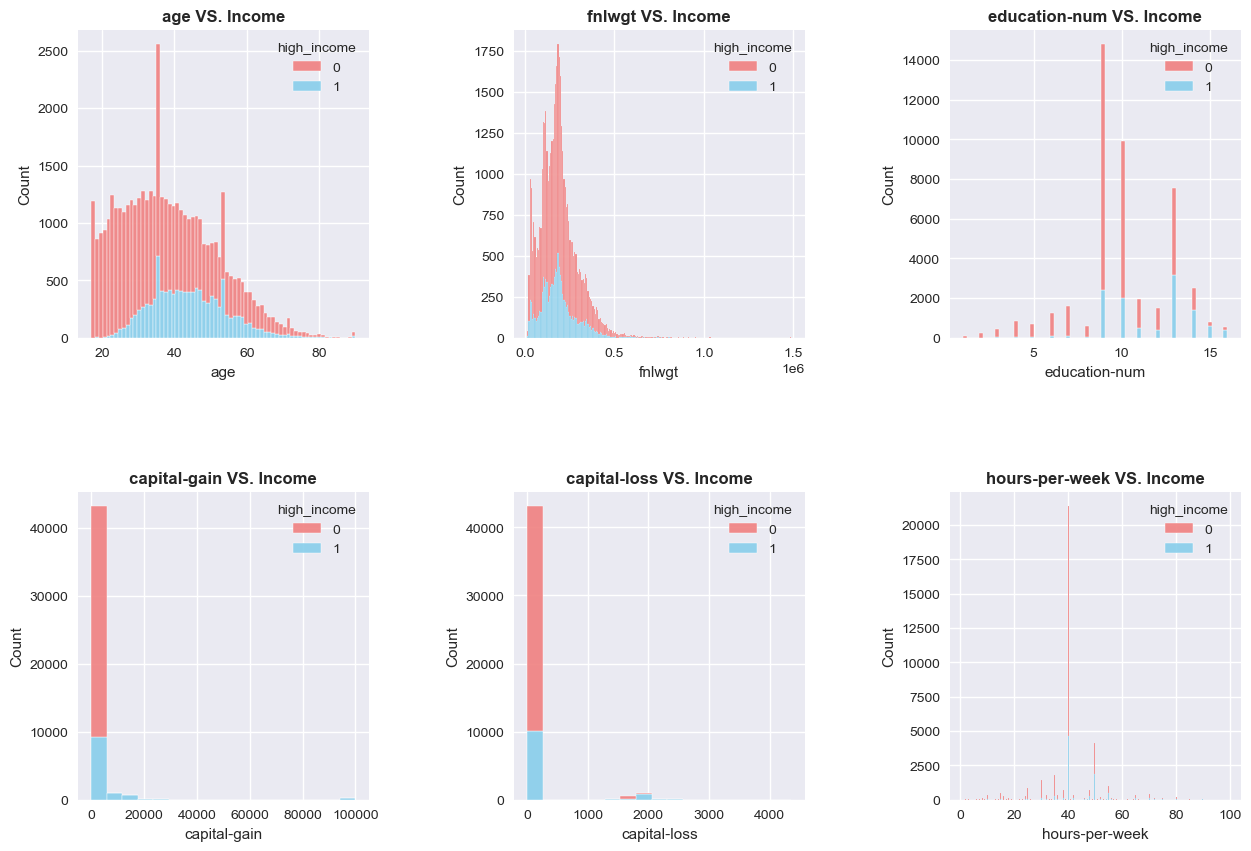

In [72]:
# Age, fnlwgt, education-num, capital-gain, capital-loss, hours-per-week (Numerical Values) VS INCOME
cols = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

plt.figure(figsize=(15, 10))

for i, col in enumerate(cols):
    plt.subplot(2, 3, i+1)
    sns.histplot(data=df, x=col, hue='high_income', multiple='stack', 
                 palette=['lightcoral', 'skyblue'], alpha=0.9, edgecolor='white')
    plt.title(f'{col} VS. Income', fontweight='bold')

plt.subplots_adjust(wspace=0.5, hspace=0.5) 

plt.show()

##### Interpretation
In general, the following visualizations emphasized the class imbalance between the low income and high income observations.

AGE VS INCOME: The data shows a rise in frequency for age 20, 35 and 55 for both low and high income individuals.

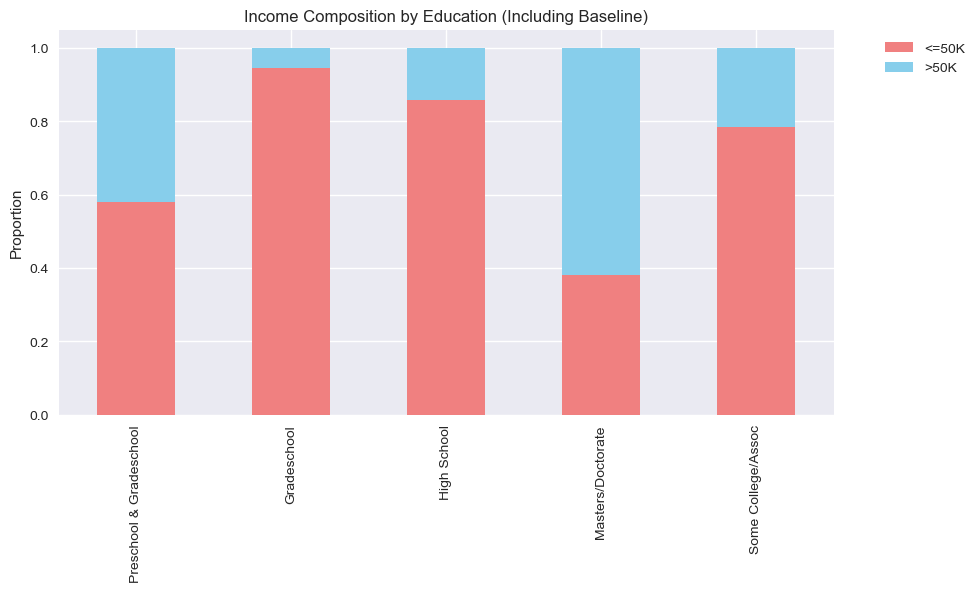

In [74]:
# EDUCATION VS. INCOME 
edu_dummies = [col for col in df.columns if col.startswith('education_')]
baseline_name = 'Preschool & Gradeschool'
plot_data = []

baseline_mask = (df[edu_dummies].sum(axis=1) == 0)
baseline_counts = df[baseline_mask]['high_income'].value_counts(normalize=True)
plot_data.append(baseline_counts)

for col in edu_dummies:
    counts = df[df[col] == 1]['high_income'].value_counts(normalize=True)
    plot_data.append(counts.reindex([0, 1], fill_value=0))

indices = [baseline_name] + [c.split('_')[-1] for c in edu_dummies]
summary_df = pd.DataFrame(plot_data, index=indices).fillna(0)

summary_df.plot(kind='bar', stacked=True, color=['lightcoral', 'skyblue'], figsize=(10, 5))
plt.title('Income Composition by Education (Including Baseline)')
plt.legend(['<=50K', '>50K'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel('Proportion')
plt.show()

##### Interpretation
The graph clearly shows the data leaning towards those individuals with income less than 50k.  
Individuals who have attained higher education (Masters/Doctorate) tend to get higher income than the other education levels. Next in line are those individuals who attained the lowest level of education (Preschool & Gradeschool), which may introduce some inconsistencies in our data.

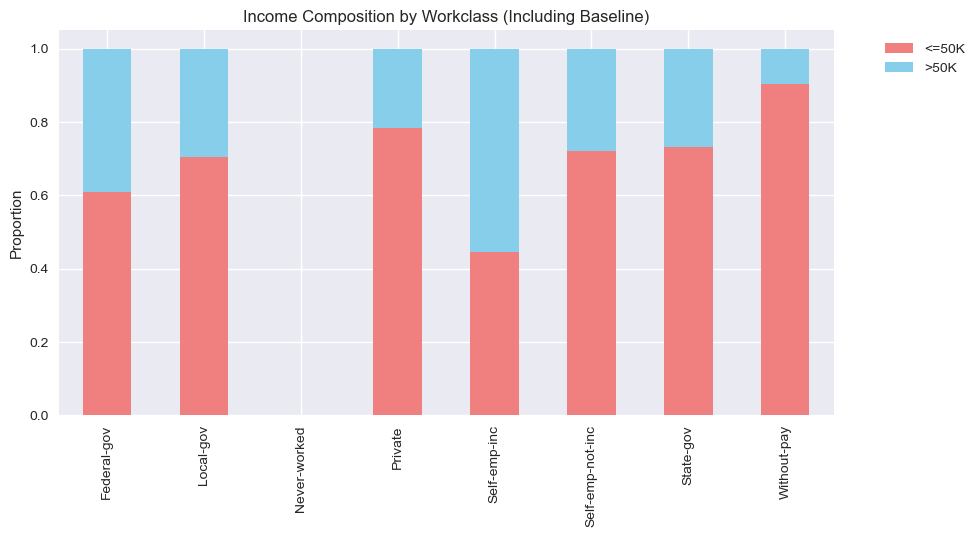

In [76]:
# WORKCLASS VS. INCOME 
wclass_dummies = [col for col in df.columns if col.startswith('workclass_')]
baseline_name = 'Federal-gov' 
plot_data = []

baseline_mask = (df[wclass_dummies].sum(axis=1) == 0)
baseline_counts = df[baseline_mask]['high_income'].value_counts(normalize=True)
plot_data.append(baseline_counts)

for col in wclass_dummies:
    counts = df[df[col] == 1]['high_income'].value_counts(normalize=True)
    plot_data.append(counts.reindex([0, 1], fill_value=0))

indices = [baseline_name] + [c.split('_')[-1] for c in wclass_dummies]
summary_df = pd.DataFrame(plot_data, index=indices).fillna(0)

summary_df.plot(kind='bar', stacked=True, color=['lightcoral', 'skyblue'], figsize=(10, 5))
plt.title('Income Composition by Workclass (Including Baseline)')
plt.legend(['<=50K', '>50K'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel('Proportion')
plt.show()

##### Interpretation
High percentage of individuals who are self-employed have income higher than 50k, with the least for those who do not have regular pay.

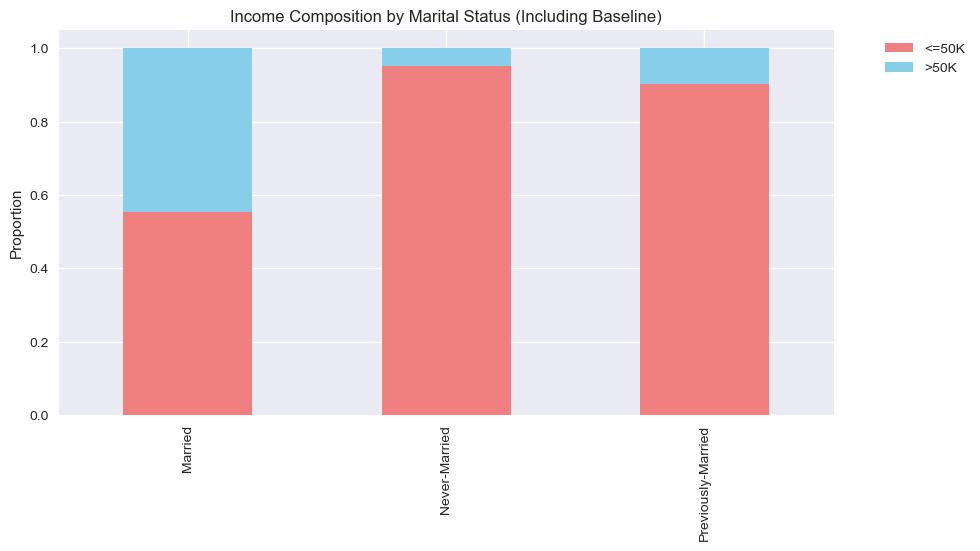

In [78]:
# MARITAL STATUS VS. INCOME (w/ Baseline)
mstatus_dummies = [col for col in df.columns if col.startswith('marital-status_')]
baseline_name = 'Married' 
plot_data = []

baseline_mask = (df[mstatus_dummies].sum(axis=1) == 0)
baseline_counts = df[baseline_mask]['high_income'].value_counts(normalize=True)
plot_data.append(baseline_counts)

for col in mstatus_dummies:
    counts = df[df[col] == 1]['high_income'].value_counts(normalize=True)
    plot_data.append(counts.reindex([0, 1], fill_value=0))

indices = [baseline_name] + [c.split('_')[-1] for c in mstatus_dummies]
summary_df = pd.DataFrame(plot_data, index=indices).fillna(0)

summary_df.plot(kind='bar', stacked=True, color=['lightcoral', 'skyblue'], figsize=(10, 5))
plt.title('Income Composition by Marital Status (Including Baseline)')
plt.legend(['<=50K', '>50K'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel('Proportion')
plt.show()

##### Interpretation
According to the graph, the individuals who are married are equal in distribution for the income levels. However, there is a significant amount of indiviuals with income less than 50k for those who were never married or previously married.

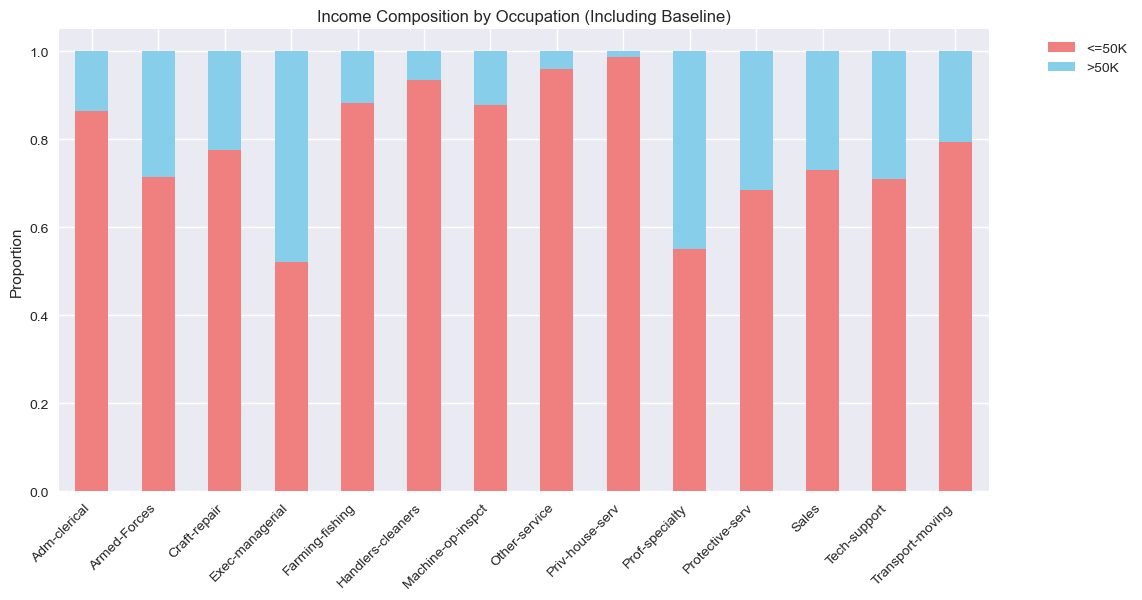

In [80]:
# OCCUPATION VS. INCOME (w/ Baseline)
occu_dummies = [col for col in df.columns if col.startswith('occupation_')]
baseline_name = 'Adm-clerical' 
plot_data = []

baseline_mask = (df[occu_dummies].sum(axis=1) == 0)
baseline_dist = df[baseline_mask]['high_income'].value_counts(normalize=True)
plot_data.append(baseline_dist.reindex([0, 1], fill_value=0))

for col in occu_dummies:
    counts = df[df[col] == 1]['high_income'].value_counts(normalize=True)
    plot_data.append(counts.reindex([0, 1], fill_value=0))

indices = [baseline_name] + [c.split('_')[-1] for c in occu_dummies]
summary_df = pd.DataFrame(plot_data, index=indices)

ax = summary_df.plot(kind='bar', stacked=True, color=['lightcoral', 'skyblue'], figsize=(12, 6))

plt.title('Income Composition by Occupation (Including Baseline)')
plt.legend(['<=50K', '>50K'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.show()

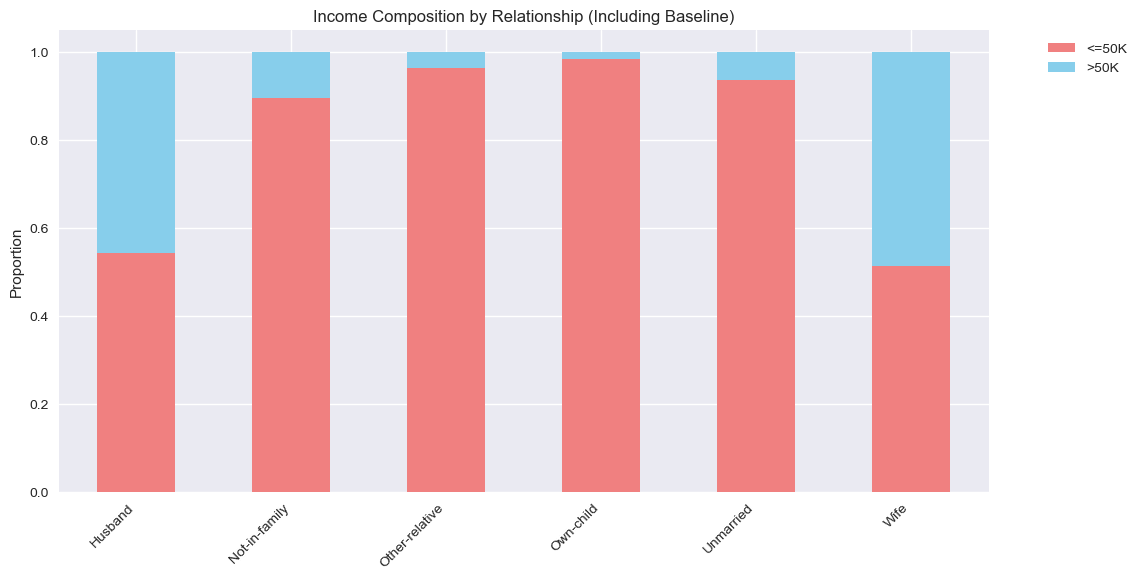

In [81]:
# RELATIONSHIP VS. INCOME (w/ Baseline)
rela_dummies = [col for col in df.columns if col.startswith('relationship_')]
baseline_name = 'Husband' 
plot_data = []

baseline_mask = (df[rela_dummies].sum(axis=1) == 0)
baseline_dist = df[baseline_mask]['high_income'].value_counts(normalize=True)
plot_data.append(baseline_dist.reindex([0, 1], fill_value=0))

for col in rela_dummies:
    counts = df[df[col] == 1]['high_income'].value_counts(normalize=True)
    plot_data.append(counts.reindex([0, 1], fill_value=0))

indices = [baseline_name] + [c.split('_')[-1] for c in rela_dummies]
summary_df = pd.DataFrame(plot_data, index=indices)

ax = summary_df.plot(kind='bar', stacked=True, color=['lightcoral', 'skyblue'], figsize=(12, 6))

plt.title('Income Composition by Relationship (Including Baseline)')
plt.legend(['<=50K', '>50K'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.show()

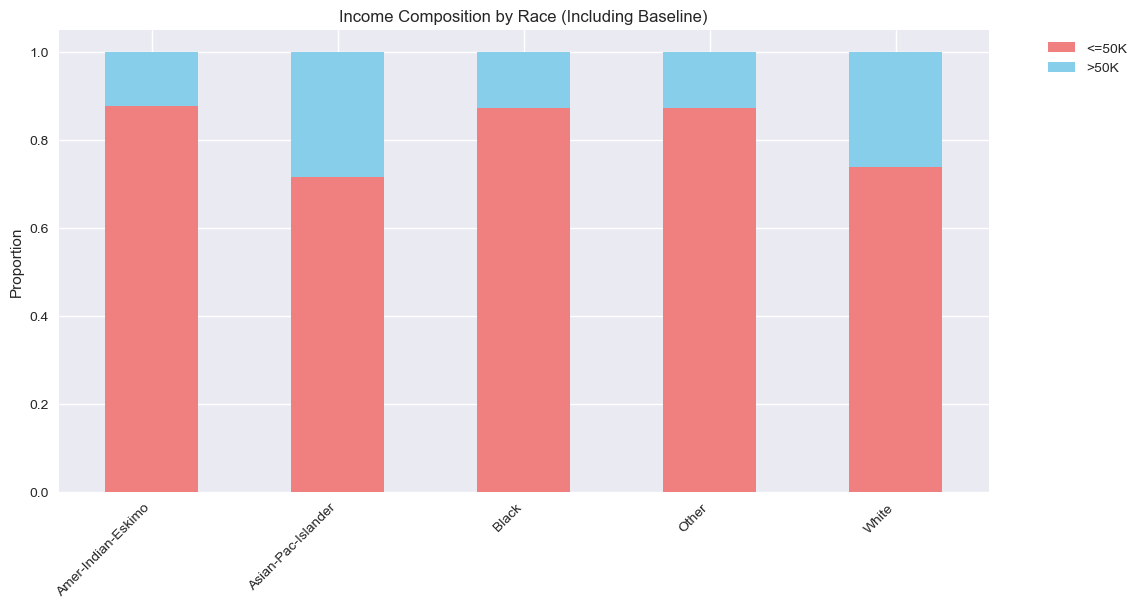

In [82]:
# RACE VS. INCOME (w/ Baseline)
race_dummies = [col for col in df.columns if col.startswith('race_')]
baseline_name = 'Amer-Indian-Eskimo' 
plot_data = []

baseline_mask = (df[race_dummies].sum(axis=1) == 0)
baseline_dist = df[baseline_mask]['high_income'].value_counts(normalize=True)
plot_data.append(baseline_dist.reindex([0, 1], fill_value=0))

for col in race_dummies:
    counts = df[df[col] == 1]['high_income'].value_counts(normalize=True)
    plot_data.append(counts.reindex([0, 1], fill_value=0))

indices = [baseline_name] + [c.split('_')[-1] for c in race_dummies]
summary_df = pd.DataFrame(plot_data, index=indices)

ax = summary_df.plot(kind='bar', stacked=True, color=['lightcoral', 'skyblue'], figsize=(12, 6))

plt.title('Income Composition by Race (Including Baseline)')
plt.legend(['<=50K', '>50K'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.show()

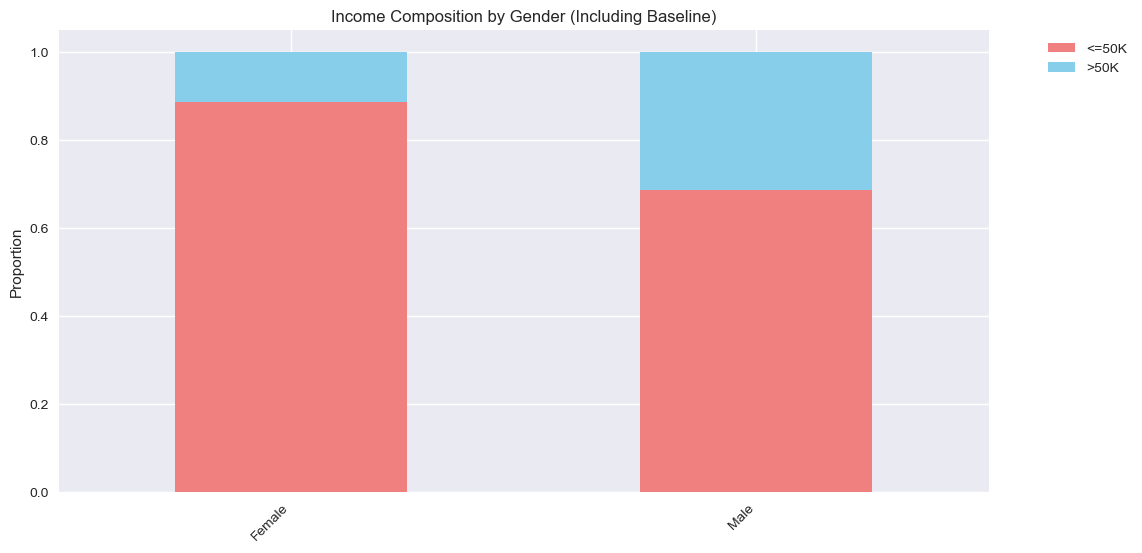

In [83]:
# SEX VS. INCOME (w/ Baseline)
sex_dummies = [col for col in df.columns if col.startswith('sex_')]
baseline_name = 'Female' 
plot_data = []

baseline_mask = (df[sex_dummies].sum(axis=1) == 0)
baseline_dist = df[baseline_mask]['high_income'].value_counts(normalize=True)
plot_data.append(baseline_dist.reindex([0, 1], fill_value=0))

for col in sex_dummies:
    counts = df[df[col] == 1]['high_income'].value_counts(normalize=True)
    plot_data.append(counts.reindex([0, 1], fill_value=0))

indices = [baseline_name] + [c.split('_')[-1] for c in sex_dummies]
summary_df = pd.DataFrame(plot_data, index=indices)

ax = summary_df.plot(kind='bar', stacked=True, color=['lightcoral', 'skyblue'], figsize=(12, 6))

plt.title('Income Composition by Gender (Including Baseline)')
plt.legend(['<=50K', '>50K'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.show()

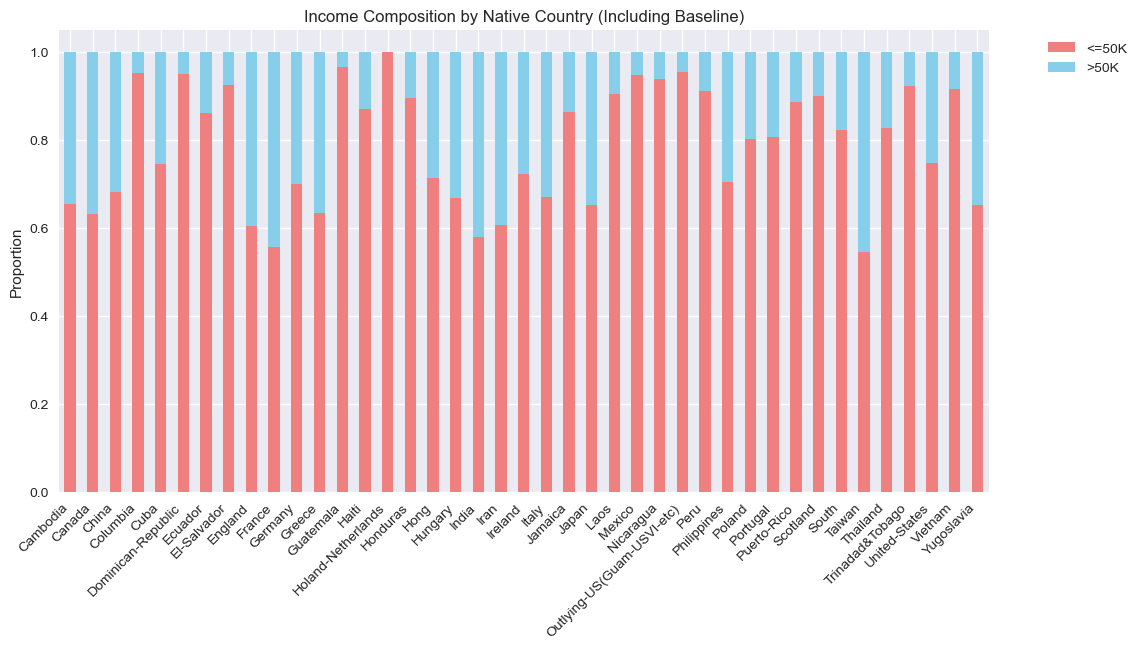

In [84]:
# NATIVE COUNTRY VS. INCOME (w/ Baseline)
ncountry_dummies = [col for col in df.columns if col.startswith('native-country_')]
baseline_name = 'Cambodia' 
plot_data = []

baseline_mask = (df[ncountry_dummies].sum(axis=1) == 0)
baseline_dist = df[baseline_mask]['high_income'].value_counts(normalize=True)
plot_data.append(baseline_dist.reindex([0, 1], fill_value=0))

for col in ncountry_dummies:
    counts = df[df[col] == 1]['high_income'].value_counts(normalize=True)
    plot_data.append(counts.reindex([0, 1], fill_value=0))

indices = [baseline_name] + [c.split('_')[-1] for c in ncountry_dummies]
summary_df = pd.DataFrame(plot_data, index=indices)

ax = summary_df.plot(kind='bar', stacked=True, color=['lightcoral', 'skyblue'], figsize=(12, 6))

plt.title('Income Composition by Native Country (Including Baseline)')
plt.legend(['<=50K', '>50K'], bbox_to_anchor=(1.05, 1), loc='upper left')
plt.ylabel('Proportion')
plt.xticks(rotation=45, ha='right')
plt.show()

Distribution of Target Variable in Percentage
high_income
0    75.215603
1    24.784397
Name: count, dtype: float64


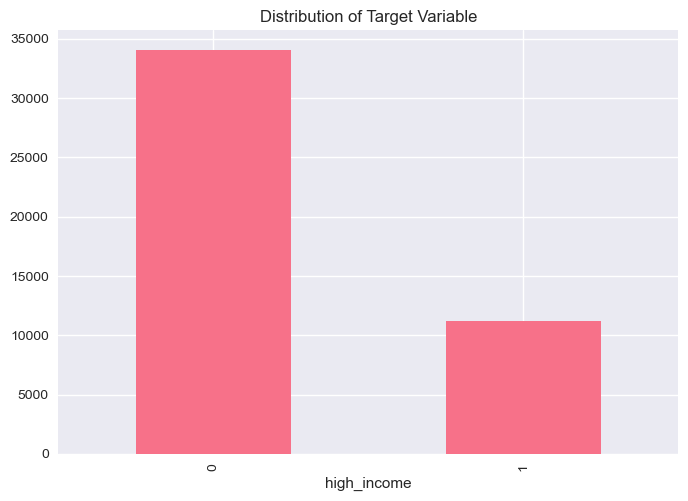

In [85]:
# DISTRIBUTION OF TARGET VARIABLE
df["high_income"].value_counts().plot(kind="bar")
plt.title("Distribution of Target Variable")

print ("Distribution of Target Variable in Percentage")
print("="*50)
print(df["high_income"].value_counts()/len(df["high_income"])*100)

##### Patterns and Data Quality Interpretation
Given the distribution of high_income target variable, only 24.78% of the dataset earns an income higher than 50,000, which pertains to a class imbalance. Because the "0" group (low income) is much larger, the model will be better at predicting who is not a high earner than who is, introducing bias to the model.

* Majority Class -> Income <= 50k (Not High Income)
* Minority Class -> Income > 50k (High Income)

### Final Cleaned Dataset

In [114]:
print("List of Final Variables after Preprocessing:")
print("="*50)
print("Number of Columns:",len(df.columns))
print("Number of Rows:", df.shape[0], "\n")
print(df.info())

List of Final Variables after Preprocessing:
Number of Columns: 83
Number of Rows: 45222 

<class 'pandas.core.frame.DataFrame'>
Index: 45222 entries, 0 to 48841
Data columns (total 83 columns):
 #   Column                                     Non-Null Count  Dtype
---  ------                                     --------------  -----
 0   age                                        45222 non-null  int64
 1   fnlwgt                                     45222 non-null  int64
 2   education-num                              45222 non-null  int64
 3   capital-gain                               45222 non-null  int64
 4   capital-loss                               45222 non-null  int64
 5   hours-per-week                             45222 non-null  int64
 6   high_income                                45222 non-null  int32
 7   education_Gradeschool                      45222 non-null  bool 
 8   education_High School                      45222 non-null  bool 
 9   education_Masters/Doctorate   

## 2. Train-Test Split and Feature Selection

### 2A. Train-Test Split

In [116]:
# TRAIN-TEST SPLIT
target = 'high_income'

# Create feature list by dropping the target column
feature_names = df.drop(columns=[target]).columns.tolist()

X = df[feature_names]
y = df[target]

# Split data into training and testing sets (80/20 split)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, shuffle=True
)

print("--- Data Split Completed: ---")
print(f"Training set size: {len(X_train):,} observations ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test set size: {len(X_test):,} observations ({len(X_test)/len(X)*100:.1f}%)")
print(f"Total observations: {len(X):,}")

train_dist = y_train.value_counts(normalize=True)
test_dist = y_test.value_counts(normalize=True)

print(f"\n--- TRAIN-TEST SPLIT RESULTS: ---")
print(f"Training set size: {len(X_train)} ({len(X_train)/len(X)*100:.1f}%)")
print(f"Test set size: {len(X_test)} ({len(X_test)/len(X)*100:.1f}%)")

print(f"\n--- Class distribution verification: ---")
print(f"Full dataset survival rate: {y.mean():.4f}")
print(f"Training set survival rate: {y_train.mean():.4f}")
print(f"Test set survival rate: {y_test.mean():.4f}")

--- Data Split Completed: ---
Training set size: 36,177 observations (80.0%)
Test set size: 9,045 observations (20.0%)
Total observations: 45,222

--- TRAIN-TEST SPLIT RESULTS: ---
Training set size: 36177 (80.0%)
Test set size: 9045 (20.0%)

--- Class distribution verification: ---
Full dataset survival rate: 0.2478
Training set survival rate: 0.2489
Test set survival rate: 0.2436


### 2B. Decision Tree for Feature Selection


DECISION TREE IMPLEMENTATION AND ANALYSIS
The best criterion is: gini
Model trained in: 0.3612 seconds

FEATURE IMPORTANCE ANALYSIS
Feature Importance Ranking:
   1. fnlwgt               0.2006
   2. capital-gain         0.1590
   3. age                  0.1153
   4. education-num        0.1122
   5. marital-status_Never-Married 0.0793
   6. hours-per-week       0.0659
   7. marital-status_Previously-Married 0.0640
   8. capital-loss         0.0378
   9. occupation_Exec-managerial 0.0095
  10. workclass_Private    0.0092
  11. workclass_Self-emp-not-inc 0.0083
  12. occupation_Craft-repair 0.0081
  13. occupation_Prof-specialty 0.0077
  14. workclass_Local-gov  0.0073
  15. occupation_Sales     0.0071
  16. sex_Male             0.0068
  17. education_High School 0.0066
  18. education_Masters/Doctorate 0.0064
  19. relationship_Wife    0.0060
  20. occupation_Transport-moving 0.0057
  21. workclass_State-gov  0.0057
  22. race_White           0.0053
  23. occupation_Machine-op-inspct 

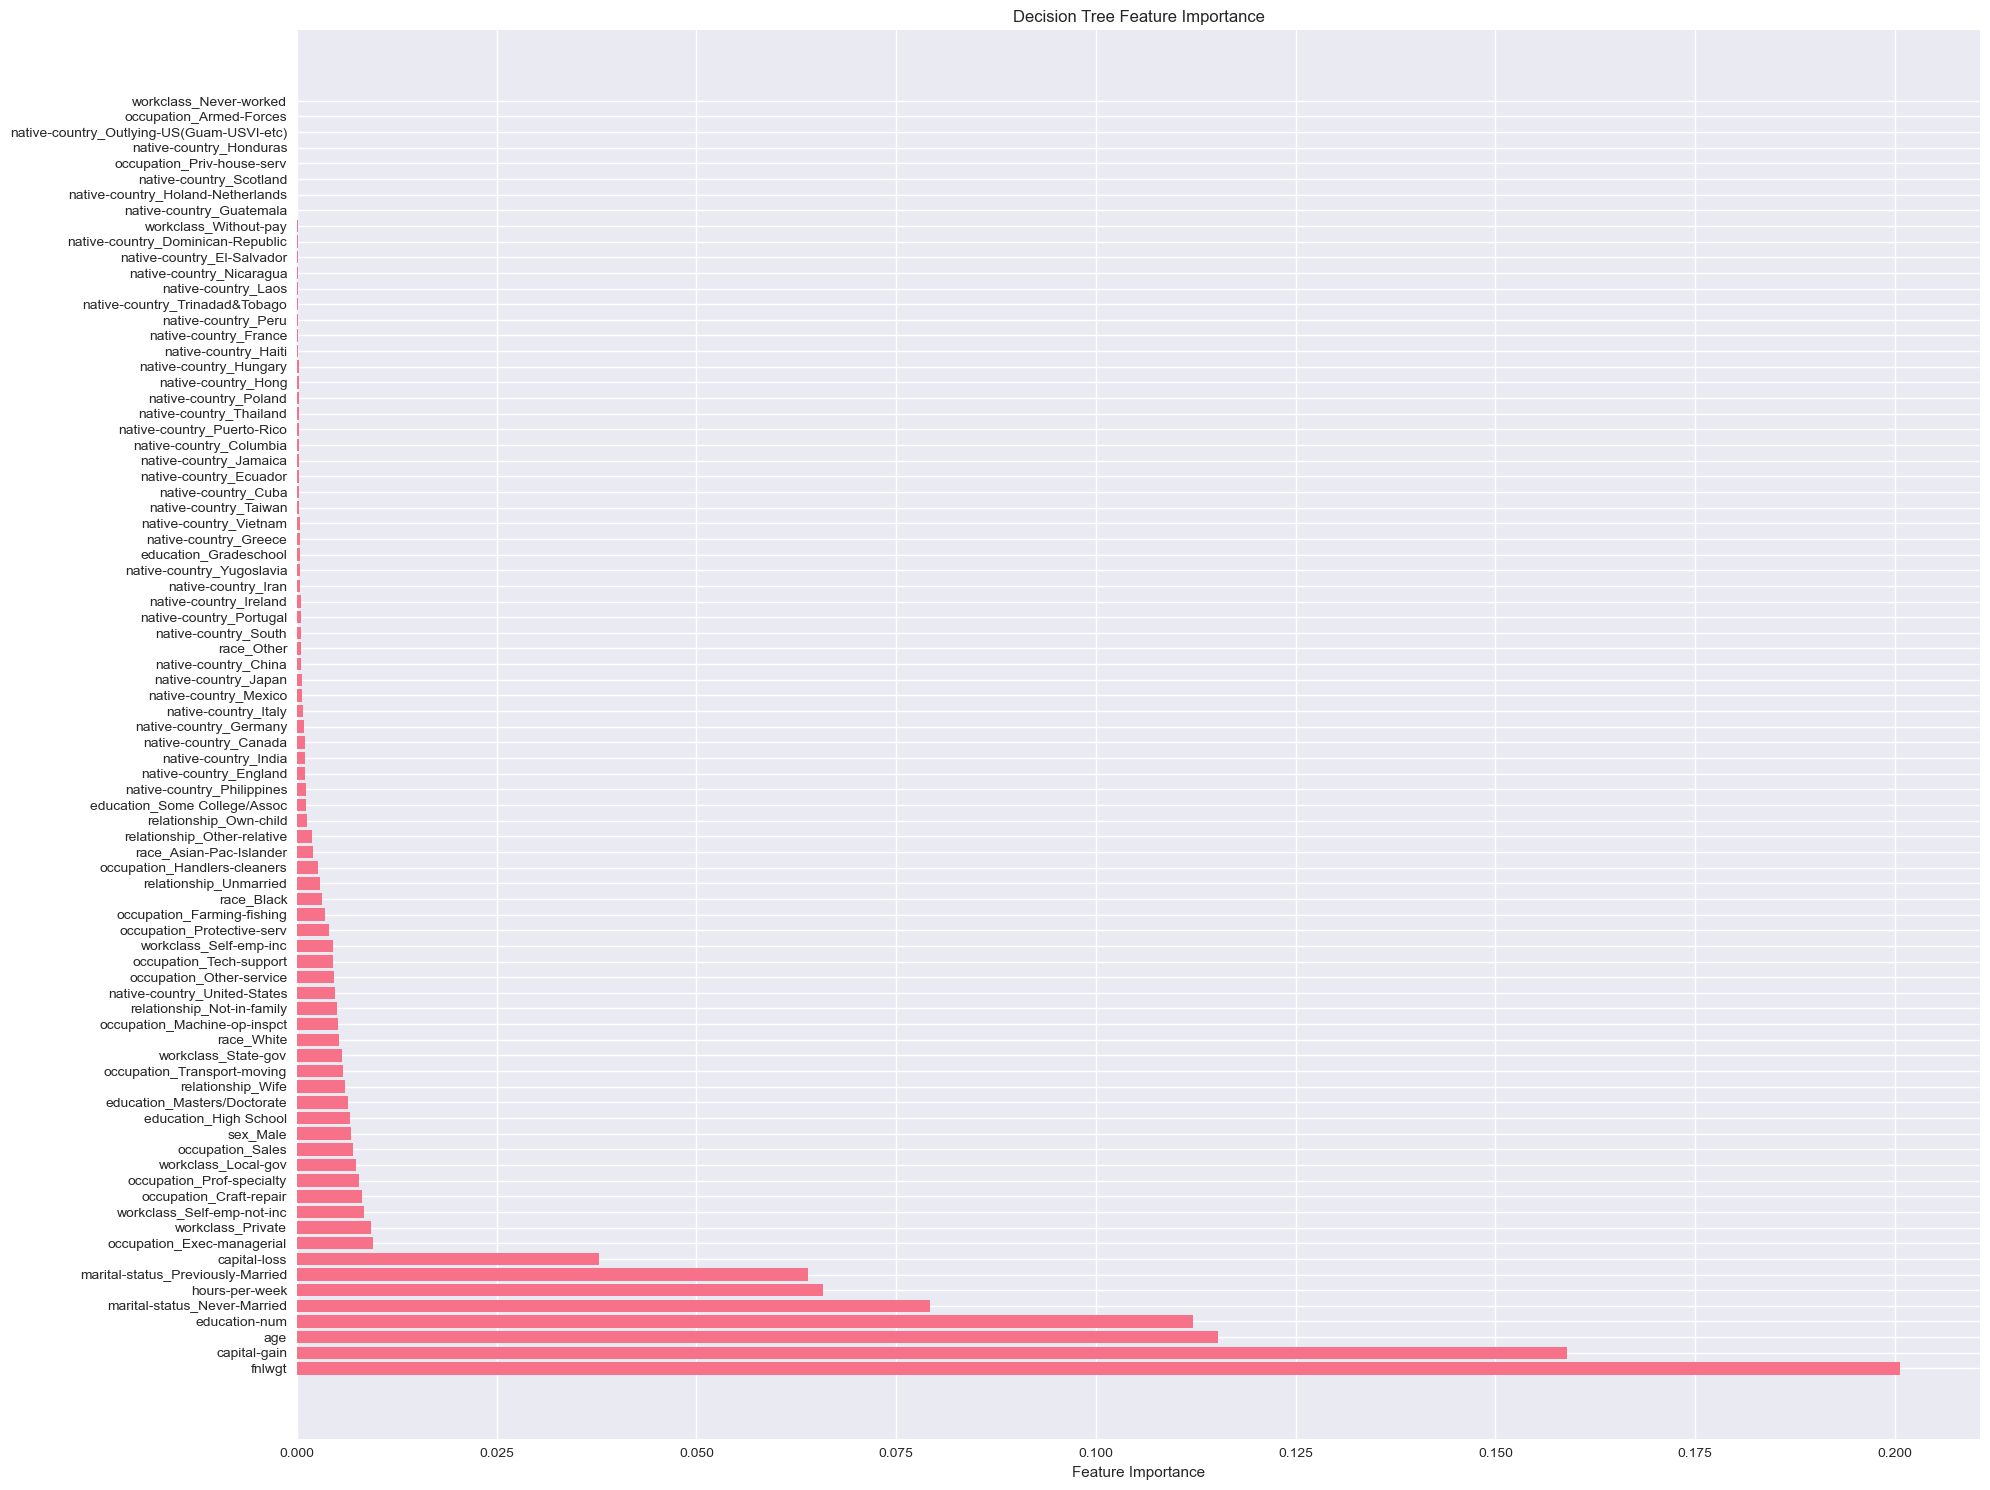

In [118]:
# ============================================================================
# DECISION TREE IMPLEMENTATION AND ANALYSIS
# ============================================================================
print("\n" + "=" * 80)
print("DECISION TREE IMPLEMENTATION AND ANALYSIS")
print("=" * 80)

feature_names = df.drop(columns=[target]).columns.tolist()

param_grid = {'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, 10]}
grid_search = GridSearchCV(DecisionTreeClassifier(), param_grid, cv=5)
grid_search.fit(X_train, y_train)
best_criterion = grid_search.best_params_['criterion']

print(f"The best criterion is: {best_criterion}")
final_dt = DecisionTreeClassifier(criterion=best_criterion, random_state=42)

start_time = time.time()
final_dt.fit(X_train, y_train)
end_time = time.time()

print(f"Model trained in: {end_time - start_time:.4f} seconds")

# ============================================================================
# Feature Importance Analysis
# ============================================================================
print("\n" + "=" * 60)
print("FEATURE IMPORTANCE ANALYSIS")
print("=" * 60)

# Get feature importances
feature_importances = final_dt.feature_importances_

# Sort features by importance
importance_indices = np.argsort(feature_importances)[::-1]

print("Feature Importance Ranking:")
for i, idx in enumerate(importance_indices):
    print(f"  {i+1:2d}. {feature_names[idx]:20} {feature_importances[idx]:.4f}")

# Plot feature importance
plt.figure(figsize=(20, 15))
plt.barh(range(len(feature_names)), feature_importances[importance_indices])
plt.yticks(range(len(feature_names)), [feature_names[i] for i in importance_indices])
plt.xlabel('Feature Importance')
plt.title('Decision Tree Feature Importance')

plt.tight_layout()
plt.show()

In [120]:
# Select the top 12 most important features based on the importance scores
importances = pd.Series(final_dt.feature_importances_, index=X.columns)
top_12_features = importances.sort_values(ascending=False).head(12)

feature_importance_dict = (
    pd.Series(final_dt.feature_importances_, index=X.columns)
    .sort_values(ascending=False)
    .head(12)
    .to_dict()
)

data = [
    {"Feature": feat, "Importance Score": score, "Selected": "Yes"} 
    for feat, score in feature_importance_dict.items()
]

final_feats = pd.DataFrame(data)
# Display the top 15 rows to see the cutoff
print("TOP 12 MOST IMPORTANT FEATURES:")
print("="*50)

print(final_feats.head(12))

TOP 12 MOST IMPORTANT FEATURES:
                              Feature  Importance Score Selected
0                              fnlwgt          0.200637      Yes
1                        capital-gain          0.158962      Yes
2                                 age          0.115258      Yes
3                       education-num          0.112173      Yes
4        marital-status_Never-Married          0.079297      Yes
5                      hours-per-week          0.065895      Yes
6   marital-status_Previously-Married          0.063953      Yes
7                        capital-loss          0.037801      Yes
8          occupation_Exec-managerial          0.009516      Yes
9                   workclass_Private          0.009226      Yes
10         workclass_Self-emp-not-inc          0.008338      Yes
11            occupation_Craft-repair          0.008111      Yes


##### Interpretation
After using the decision tree feature analysis, we have the 12 top features that provides the most value and information to our model.

In [122]:
# Create the new reduced feature set
top_12_features = list(feature_importance_dict.keys())
X_train_selected = X_train[top_12_features]
X_test_selected = X_test[top_12_features]

print("Train and Test sets properly splitted.")

print(f"\n--- TRAIN-TEST SPLIT RESULTS: ---")
print(f"Training set size: {len(X_train_selected)} ({len(X_train_selected)/len(X)*100:.1f}%)")
print(f"Test set size: {len(X_test_selected)} ({len(X_test_selected)/len(X)*100:.1f}%)")

print(f"\n--- Class distribution verification: ---")
print(f"Full dataset survival rate: {y.mean():.4f}")
print(f"Training set survival rate: {y_train.mean():.4f}")
print(f"Test set survival rate: {y_test.mean():.4f}")

Train and Test sets properly splitted.

--- TRAIN-TEST SPLIT RESULTS: ---
Training set size: 36177 (80.0%)
Test set size: 9045 (20.0%)

--- Class distribution verification: ---
Full dataset survival rate: 0.2478
Training set survival rate: 0.2489
Test set survival rate: 0.2436


## 3. Model Training and Comparison

#### 3A. Model Training
After properly splitting the data into train and test sets, we can start the model training to see which model best suits this classification problem.

#### Linear Probability Model

In [124]:
# Convert any booleans to integers
X_train_selected = X_train_selected.astype(float)
X_test_selected = X_test_selected.astype(float)

In [126]:
print("\n" + "=" * 60)
print("MODEL 1: LINEAR PROBABILITY MODEL (LPM) SUMMARY")
print("=" * 60)

# Train the Model to LPM
X_train_sm = sm.add_constant(X_train_selected)
lpm_model = sm.OLS(y_train, X_train_sm).fit()

print(lpm_model.summary())


MODEL 1: LINEAR PROBABILITY MODEL (LPM) SUMMARY
                            OLS Regression Results                            
Dep. Variable:            high_income   R-squared:                       0.343
Model:                            OLS   Adj. R-squared:                  0.343
Method:                 Least Squares   F-statistic:                     1576.
Date:                Thu, 05 Mar 2026   Prob (F-statistic):               0.00
Time:                        20:49:36   Log-Likelihood:                -13391.
No. Observations:               36177   AIC:                         2.681e+04
Df Residuals:                   36164   BIC:                         2.692e+04
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------

#### Logistic Regression

In [128]:
print("\n" + "=" * 60)
print("MODEL 2: LOGISTIC REGRESSION SUMMARY")
print("=" * 60)

# Train the Model to Logit
X_train_logit = sm.add_constant(X_train_selected)
logit_model = sm.Logit(y_train, X_train_logit).fit()

print(logit_model.summary())


MODEL 2: LOGISTIC REGRESSION SUMMARY
Optimization terminated successfully.
         Current function value: 0.340315
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:            high_income   No. Observations:                36177
Model:                          Logit   Df Residuals:                    36164
Method:                           MLE   Df Model:                           12
Date:                Thu, 05 Mar 2026   Pseudo R-squ.:                  0.3935
Time:                        20:50:08   Log-Likelihood:                -12312.
converged:                       True   LL-Null:                       -20300.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                        coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
const                   

#### K-Nearest Neighbors (K=9)

In [130]:
# ============================================================================
# MODEL 3: K-NEAREST NEIGHBORS
# ============================================================================
print("\n" + "=" * 60)
print("MODEL 3: K-NEAREST NEIGHBORS")
print("=" * 60)

# 1. Scaling the data (Mandatory for KNN)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_selected)
X_test_scaled = scaler.transform(X_test_selected)

# 2. Initializing with default parameters (n_neighbors=5)
final_knn = KNeighborsClassifier()

# 3. Training and Accuracy calculation
start_time = time.time()
final_knn.fit(X_train_scaled, y_train)
train_accuracy = final_knn.score(X_train_scaled, y_train)
end_time = time.time()

print(f"Model Training Complete.")
print(f"- Training Accuracy: {train_accuracy:.4f}")
print(f"- Training Time: {end_time - start_time:.4f} seconds")

# ============================================================================
# FEATURE IMPORTANCE (Permutation Importance)
# ============================================================================
print("\n" + "=" * 60)
print("KNN FEATURE IMPORTANCE")
print("=" * 60)

# Using X_test_scaled to see how well the features generalize to new data
perm_importance = permutation_importance(
    final_knn, X_test_scaled, y_test, n_repeats=5, random_state=42
)

feature_names = X_train_selected.columns
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance Score': perm_importance.importances_mean,
    'Std Dev': perm_importance.importances_std
}).sort_values(by='Importance Score', ascending=False)

# Display the Top 12 Ranking
print("KNN Feature Importance Ranking:")
print("-" * 40)
print(importance_df.to_string(index=False))


MODEL 3: K-NEAREST NEIGHBORS
Model Training Complete.
- Training Accuracy: 0.8755
- Training Time: 5.0668 seconds

KNN FEATURE IMPORTANCE
KNN Feature Importance Ranking:
----------------------------------------
                          Feature  Importance Score  Std Dev
     marital-status_Never-Married          0.044688 0.001958
marital-status_Previously-Married          0.042344 0.003025
                    education-num          0.038850 0.001396
                     capital-gain          0.030558 0.001337
                              age          0.014306 0.002466
       workclass_Self-emp-not-inc          0.007828 0.000433
                   hours-per-week          0.006501 0.001406
                     capital-loss          0.006457 0.000698
       occupation_Exec-managerial          0.004909 0.000647
                           fnlwgt          0.002919 0.001380
                workclass_Private          0.002875 0.001999
          occupation_Craft-repair          0.001128 0.00

#### Decision Tree


MODEL 4: DECISION TREE ANALYSIS
Model Training Complete.
- Training Accuracy: 0.9998
- Training Time: 0.1717 seconds

DECISION TREE FEATURE IMPORTANCE (GINI)
Decision Tree Feature Importance Ranking:
----------------------------------------
                          Feature  Importance Score
                           fnlwgt          0.268136
                     capital-gain          0.161240
                              age          0.129180
                    education-num          0.129159
     marital-status_Never-Married          0.079435
                   hours-per-week          0.073989
marital-status_Previously-Married          0.064145
                     capital-loss          0.038710
                workclass_Private          0.018180
          occupation_Craft-repair          0.014430
       occupation_Exec-managerial          0.011701
       workclass_Self-emp-not-inc          0.011695


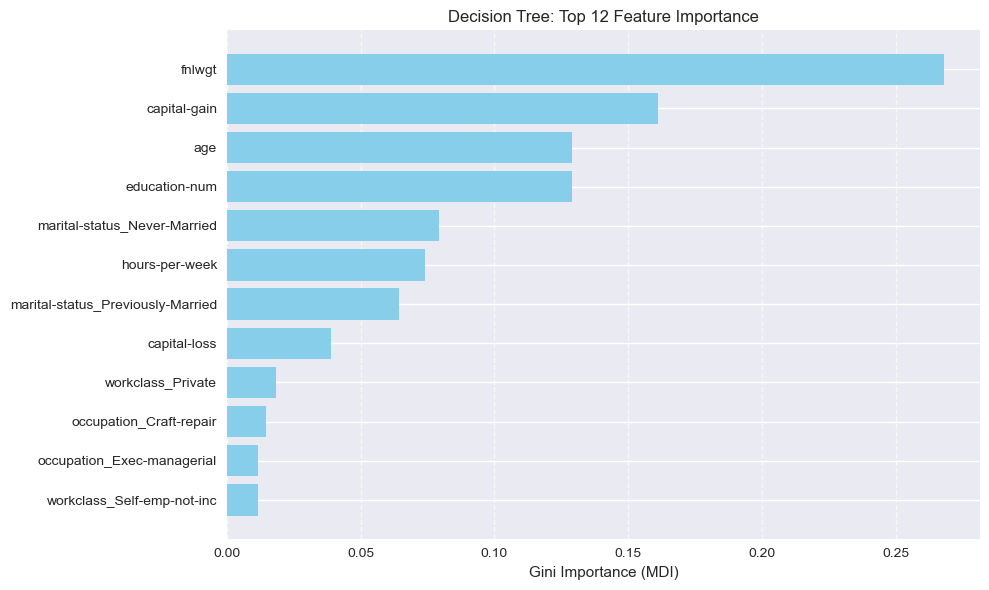

In [132]:
print("\n" + "=" * 60)
print("MODEL 4: DECISION TREE ANALYSIS")
print("=" * 60)

# 1. Initialize with Default Parameters 
final_dt = DecisionTreeClassifier(random_state=42)

# 2. Fit Model and Calculate Training Accuracy
start_time = time.time()
final_dt.fit(X_train_selected, y_train)
train_accuracy = final_dt.score(X_train_selected, y_train)
end_time = time.time()

print(f"Model Training Complete.")
print(f"- Training Accuracy: {train_accuracy:.4f}")
print(f"- Training Time: {end_time - start_time:.4f} seconds")

# ============================================================================
# FEATURE IMPORTANCE
# ============================================================================
print("\n" + "=" * 60)
print("DECISION TREE FEATURE IMPORTANCE (GINI)")
print("=" * 60)

# Extract built-in feature importance
importances = final_dt.feature_importances_
feature_names = X_train_selected.columns

# Create a DataFrame for display
dt_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance Score': importances
}).sort_values(by='Importance Score', ascending=False)

# Display the Top 12 Ranking
print("Decision Tree Feature Importance Ranking:")
print("-" * 40)
print(dt_importance_df.to_string(index=False))

# Visualization of feature importances
dt_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

dt_importance_df = dt_importance_df.sort_values(by='Importance', ascending=True)
top_12 = dt_importance_df.tail(12)

# Plot the Feature Importances
plt.figure(figsize=(10, 6))
plt.barh(top_12['Feature'], top_12['Importance'], color='skyblue')

plt.xlabel('Gini Importance (MDI)')
plt.title('Decision Tree: Top 12 Feature Importance')
plt.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

##### KNN Vs. Decision Tree
The Top 12 Features from the Decision Tree and the KNN differ from one another due to KNN's unique scaling. According to KNN, the most important features are marital-status_Never-Married, marital-status_Previously-Married, education-num, & capital-gain. Features like fnlwgt (0.0013) and occupation_Craft-repair (0.0010) are at the bottom. The model barely uses them. If removed, the model’s accuracy would likely stay almost exactly the same. For the decision tree, fnlwgt was the most important feature, but KNN realized that this feature is only noise and doesn't help group similar earners together; it is insignificant to the model's performance.

#### Bagging

In [134]:
print("\n" + "=" * 60)
print("MODEL 5: BAGGING")
print("=" * 60)

# Initialize the Model
bagging_model = BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=100,
    random_state=42
)

# Fit the Model
start_time = time.time()
bagging_model.fit(X_train_selected, y_train)
bagging_train_acc = bagging_model.score(X_train_selected, y_train)
end_time = time.time()

print(f"\nBagging (100 Decision Trees):")
print("Model fitting complete.")
print(f"• Training Accuracy: {bagging_train_acc:.4f}")
print(f"- Training Time: {end_time - start_time:.4f} seconds")


MODEL 5: BAGGING

Bagging (100 Decision Trees):
Model fitting complete.
• Training Accuracy: 0.9998
- Training Time: 10.9406 seconds


##### How does bagging reduce variance compared to a single decision tree?
Bagging is an optimization deduced from a single decision tree by an ensemble of multiple trees rather than relying on just one. A single decision tree is prone to overfitting, resulting into high variance, while Bagging uses bootstrapping technique that allows to train multiple training subsets using sampling with replacement. Each tree is trained on a different subset, and their individual predictions are then aggregated. This process cancels out the random errors of individual trees, resulting in a more stable model with significantly lower variance.

#### Random Forest

In [136]:
print("\n" + "=" * 60)
print("MODEL 6: RANDOM FOREST")
print("=" * 60)

# Initialize the Model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    max_depth=10
)

# Fit the Model
start_time = time.time()
rf_model.fit(X_train_selected, y_train)
rf_train_score = rf_model.score(X_train_selected, y_train)
end_time = time.time()

print("Model fitting complete.")
print("Initial Results:")
print(f"• Training Accuracy of Random Forest: {rf_train_score:.4f}")
print(f"- Training Time: {end_time - start_time:.4f} seconds")


MODEL 6: RANDOM FOREST
Model fitting complete.
Initial Results:
• Training Accuracy of Random Forest: 0.8622
- Training Time: 2.2292 seconds


##### How does Random Forest differ from standard Bagging?
In contrast to Bagging, Random Forest takes into consideration proper feature stratification/randomness. Bagging uses all available features for every split, which means it could lead to only using the strong predictors for each time. Random Forest utilizes all features and makes sures that its usage is aas balanced as other predictors in tree. This forces the ensemble to explore "weaker" predictors that might otherwise be ignored, resulting in a more diverse set of trees and lower overall model variance.

In [138]:
#============================================================================
# FINDING THE BEST MAX DEPTH and N_ESTIMATORS 
#============================================================================
param_grid = {
    'max_depth': [None, 2, 5, 10],
    'n_estimators': [50, 100, 200, 500]
}

grid_search = GridSearchCV(rf_model, param_grid, cv=5, n_jobs=2, verbose=2)

start_total = time.time()
grid_search.fit(X_train, y_train) 
end_total = time.time()

results_df = pd.DataFrame(grid_search.cv_results_)
time_analysis = results_df[['param_max_depth', 'param_n_estimators', 'mean_test_score', 'mean_fit_time']]
time_analysis = time_analysis.sort_values(by='mean_test_score', ascending=False)

# --- Display Results ---
print("=" * 60)
print("RANDOM FOREST: GRID SEARCH TIME & ACCURACY ANALYSIS")
print("=" * 60)

print(time_analysis.to_string(index=False))

print("-" * 60)
print(f"Total Grid Search Time: {end_total - start_total:.4f} seconds")
print(f"Best Max Depth: {grid_search.best_params_['max_depth']}")
print(f"Best N Estimators: {grid_search.best_params_['n_estimators']}")
print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits
RANDOM FOREST: GRID SEARCH TIME & ACCURACY ANALYSIS
param_max_depth param_n_estimators  mean_test_score  mean_fit_time
             10                500         0.852973       7.814109
             10                200         0.852807       3.193992
             10                 50         0.852199       0.880706
           None                500         0.852199      18.201696
             10                100         0.851757       1.714528
           None                200         0.851756       6.733867
           None                100         0.850872       3.339180
           None                 50         0.850347       1.617627
              5                200         0.829063       2.164215
              5                500         0.828786       5.319911
              5                100         0.827874       1.082469
              5                 50         0.827321       0.521354
              2 

After doing grid search cross-validation, the best parameters for this random forest model is max_depth=10 and n_estimators=500. These parameters will be applied for the optimized random forest below.


MODEL 6: RANDOM FOREST
Model fitting complete.
Final Results:
• Training Accuracy of Random Forest: 0.8625
- Training Time: 11.2504 seconds

----------------------------------------
Random Forest Feature Importance Ranking:
----------------------------------------
                          Feature  Importance
                     capital-gain    0.235214
                    education-num    0.187377
     marital-status_Never-Married    0.158165
marital-status_Previously-Married    0.114482
                              age    0.103416
                     capital-loss    0.067448
                   hours-per-week    0.063442
       occupation_Exec-managerial    0.035645
                           fnlwgt    0.020439
       workclass_Self-emp-not-inc    0.006575
                workclass_Private    0.005087
          occupation_Craft-repair    0.002710


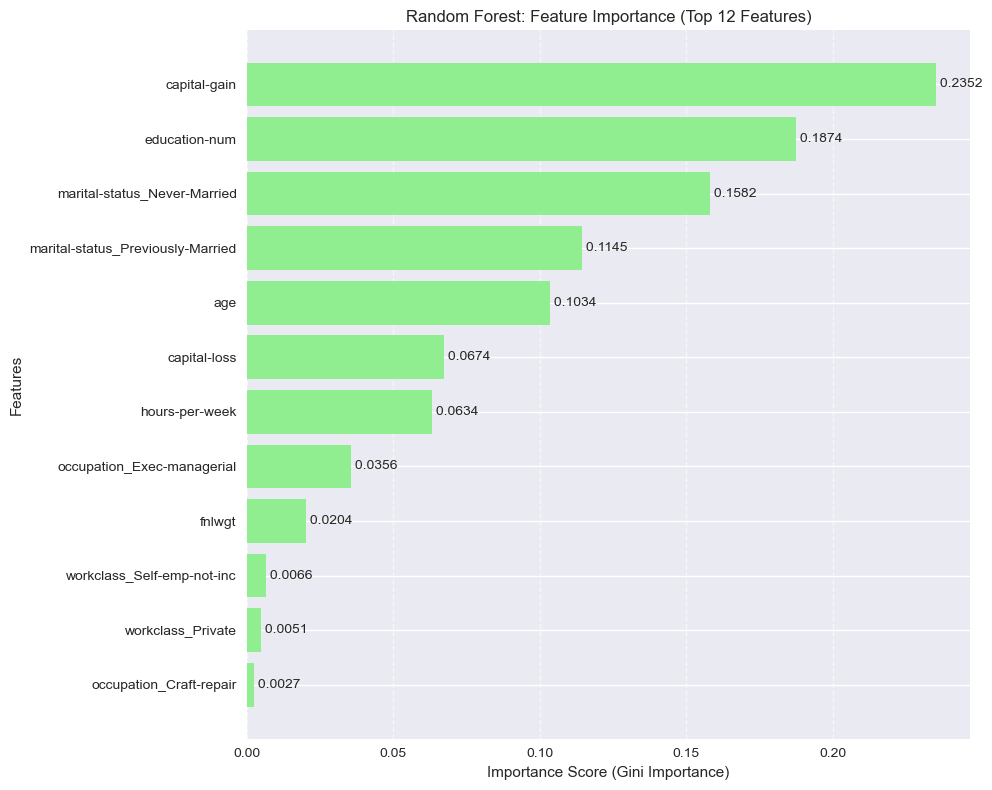

In [140]:
# ============================================================================
# RANDOM FOREST: BEST FIT AND FEATURE IMPORTANCE
# ============================================================================
print("\n" + "=" * 60)
print("MODEL 6: RANDOM FOREST")
print("=" * 60)

# Initialize the Model
best_rf = RandomForestClassifier(
    n_estimators=500, # ---> BEST N_ESTIMATOR = 500
    random_state=42,
    max_depth=10 # ---> BEST MAx_DEPTH = 10
)

# Fit the Model
start_time = time.time()
best_rf.fit(X_train_selected, y_train)
rf_train_score = best_rf.score(X_train_selected, y_train)
end_time = time.time()

print("Model fitting complete.")
print("Final Results:")
print(f"• Training Accuracy of Random Forest: {rf_train_score:.4f}")
print(f"- Training Time: {end_time - start_time:.4f} seconds")

# ============================================================================
# FEATURE IMPORTANCE
# ============================================================================
best_rf_importance_df = pd.DataFrame({
    'Feature': X_train_selected.columns,
    'Importance': best_rf.feature_importances_
})

best_rf_importance_df = best_rf_importance_df.sort_values(by='Importance', ascending=True)

print("\n" +"-" * 40)
print("Random Forest Feature Importance Ranking:")
print("-" * 40)

print(best_rf_importance_df.sort_values(by='Importance', ascending=False).to_string(index=False))

# Plot the Feature Importances
plt.figure(figsize=(10, 8))
plt.barh(best_rf_importance_df['Feature'], best_rf_importance_df['Importance'], color='lightgreen')

plt.xlabel('Importance Score (Gini Importance)')
plt.ylabel('Features')
plt.title('Random Forest: Feature Importance (Top 12 Features)')
plt.grid(axis='x', linestyle='--', alpha=0.6)

for index, value in enumerate(best_rf_importance_df['Importance']):
    plt.text(value, index, f' {value:.4f}', va='center', fontsize=10)

plt.tight_layout()
plt.show()

##### Brief note (2-3 sentences): How does Random Forest reduce variance through parallel ensemble construction?
Random Forest reduces variance by training multiple decision trees independently in parallel given the random subsets of features taken from the bootstrapping method, which means the trees will look different from one another. Then, by averaging the majority votes for each tree, it reduces the errors of any single tree creating a well-generalized model. 

#### Adaptive Boosting

In [142]:
print("\n" + "=" * 60)
print("MODEL 7: Adaptive Boosting")
print("=" * 60)

# Test different numbers of weak learners
n_estimators_list = [1, 5, 10, 25, 50, 100, 200]
print(f"{'Weak Learners':<15} {'Train Acc':<15} {'Test Acc':<15} {'Time (s)':<10}")
print("-" * 60)

# Store the results to see the best one later
ada_train_acc = 0
ada_test_acc = 0
best_test_acc = 0
best_n = 0

for n_estimators in n_estimators_list:
    # Initialize the model
    ada_model = AdaBoostClassifier( 
        estimator=DecisionTreeClassifier(max_depth=1),
        n_estimators=n_estimators,
        random_state=42,
        algorithm='SAMME'
    )

    # Fit and Time the Model
    start_time = time.time()
    ada_model.fit(X_train_selected, y_train)
    end_time = time.time()
    
    # Get scores
    train_acc = ada_model.score(X_train_selected, y_train)
    test_acc = ada_model.score(X_test_selected, y_test)
    duration = end_time - start_time

    # Print results for this specific iteration
    print(f"{n_estimators:<15} {train_acc:<15.4f} {test_acc:<15.4f} {duration:<10.4f}")
    
    # Track the best performing n_estimators
    if test_acc > best_test_acc:
        best_test_acc = test_acc
        ada_test_acc = test_acc
        ada_train_acc = train_acc
        best_n = n_estimators

print("-" * 60)
print(f"Model fitting complete.")
print(f"• Final Training Accuracy: {ada_train_acc:.4f}")
print(f"• Final Test Accuracy: {ada_test_acc:.4f} using {best_n} weak learners.")
print(f"- Training Time: {end_time - start_time:.4f} seconds")


MODEL 7: Adaptive Boosting
Weak Learners   Train Acc       Test Acc        Time (s)  
------------------------------------------------------------
1               0.7952          0.7992          0.0278    
5               0.8351          0.8392          0.0739    
10              0.8370          0.8413          0.1595    
25              0.8421          0.8478          0.4075    
50              0.8462          0.8537          0.7990    
100             0.8468          0.8552          1.5821    
200             0.8484          0.8564          3.1055    
------------------------------------------------------------
Model fitting complete.
• Final Training Accuracy: 0.8484
• Final Test Accuracy: 0.8564 using 200 weak learners.
- Training Time: 3.1055 seconds


Given the number of weak learners, we will be using the n_estimators=200 for the best possible results.

##### Interpretation
In adaptive boosting, we understand that the outcome of the prediction increases as the number of weak learners combined increases as well.

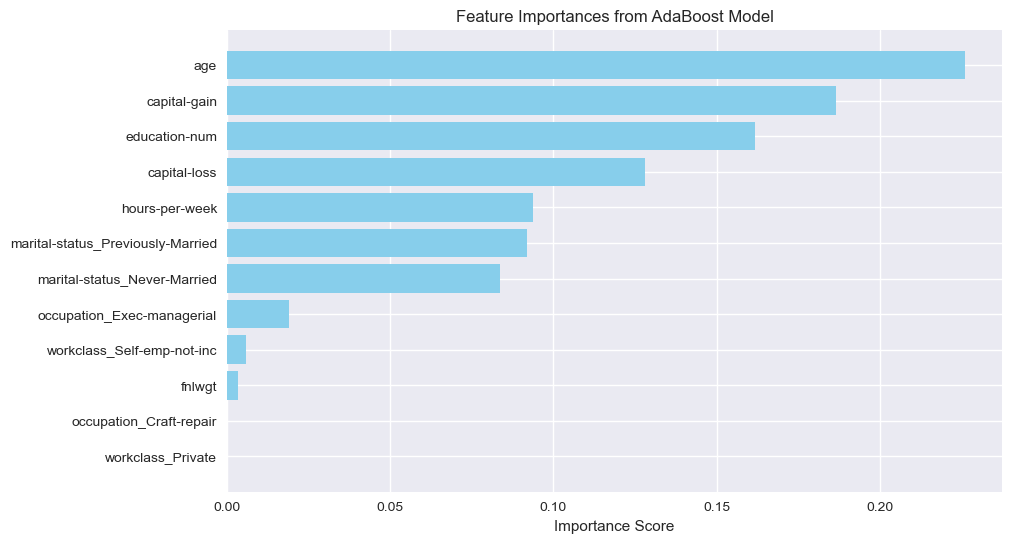

In [161]:
# -------------------------------------------------
# ADABOOST'S FEATURE IMPORTANCE
# -------------------------------------------------

importances = ada_model.feature_importances_

ada_feature_importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# 4. Plotting
plt.figure(figsize=(10, 6))
plt.barh(ada_feature_importance_df['Feature'], ada_feature_importance_df['Importance'], color='skyblue')
plt.xlabel('Importance Score')
plt.title('Feature Importances from AdaBoost Model')
plt.show()

##### Detailed explanation (4-5 sentences):    
How does AdaBoost sequentially focus on misclassified samples?    
What is the role of sample weights in AdaBoost?   
Why use weak learners (stumps with max_depth=1)?   
How does the learning_rate parameter affect the algorithm?   

As AdaBoost combines weak learners to create strong predictors, it increases the weight of the misclassified data points for every iteration to ensure that the model learns from its mistakes until the overall error is minimized. The weak learners are used in groups because the model follows the principle that when a large group of people performs a certain task together, even if they are on the average level, can create a better output than one genius-level individual. This ensures that the final model can be complex enough without overfitting. For the learning rate, this determines how much each new tree contributes to the final prediction. It has an inverse relationship with n_estimators as the lower the learning rate, the higher the n_estimators should be to provide the model ample time/steps to reach good results. 

#### Gradient Boosting

In [146]:
print("\n" + "=" * 60)
print("MODEL 8: Gradient Boosting")
print("=" * 60)

# Initialize the Model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=1,
    random_state=42
)

# Fit the Gradient Boosting Model
start_time = time.time()
gb_model.fit(X_train_selected, y_train)
gb_train_score = gb_model.score(X_train_selected, y_train)
gb_test_score = gb_model.score(X_test_selected, y_test)
end_time = time.time()

print(f"Model fitting complete.")
print (f"Initial Results:")
print(f"• Final Training Accuracy: {gb_train_score:.4f}")
print(f"• Final Test Accuracy: {gb_test_score:.4f}")
print(f"- Training Time: {end_time - start_time:.4f} seconds")


MODEL 8: Gradient Boosting
Model fitting complete.
Initial Results:
• Final Training Accuracy: 0.8420
• Final Test Accuracy: 0.8479
- Training Time: 1.3815 seconds


In [148]:
#============================================================================
# FINDING THE BEST MAX DEPTH and N_ESTIMATORS 
#============================================================================

# Define the combinations you want to test
param_grid = {
    'max_depth': [1, 2, 3, 5],
    'n_estimators': [50, 100, 200, 500],
    'learning_rate': [0.01, 0.05, 0.1, 0.2]
}

# cv=5 means it will split your data 5 different ways to ensure the result is stable
grid_search = GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid, cv=5,  n_jobs=2, verbose=2)

# 3. Time the entire process
start_total = time.time()
grid_search.fit(X_train_selected, y_train)
end_total = time.time()

results_df = pd.DataFrame(grid_search.cv_results_)
time_analysis = results_df[['param_max_depth', 'param_n_estimators', 'mean_test_score', 'mean_fit_time']]
time_analysis = time_analysis.sort_values(by='mean_test_score', ascending=False)

# Results
print("=" * 60)
print("GRID SEARCH TIME & ACCURACY ANALYSIS")
print("=" * 60)

print(time_analysis.to_string(index=False))

print("-" * 60)
print(f"Total Grid Search Time: {end_total - start_total:.4f} seconds")
print(f"Best Max Depth: {grid_search.best_params_['max_depth']}")
print(f"Best N Estimators: {grid_search.best_params_['n_estimators']}")
print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

Fitting 5 folds for each of 64 candidates, totalling 320 fits
GRID SEARCH TIME & ACCURACY ANALYSIS
param_max_depth param_n_estimators  mean_test_score  mean_fit_time
              3                500         0.862537      12.428627
              5                200         0.862012       8.061527
              5                100         0.861570       4.051601
              5                500         0.861542      20.157984
              3                500         0.861348      12.706700
              3                200         0.861321       4.964158
              5                200         0.861238       8.121492
              5                 50         0.861127       2.029984
              2                500         0.861100       8.572192
              2                500         0.860934       8.632709
              3                200         0.860906       4.999628
              3                500         0.860823      12.394295
              5               

In [155]:
print("-" * 60)
print("BEST PARAMETERS FOR GRADIENT BOOSTING:")
print(f"Total Grid Search Time: {end_total - start_total:.4f} seconds")
print(f"Best Max Depth: {grid_search.best_params_['max_depth']}")
print(f"Best N Estimators: {grid_search.best_params_['n_estimators']}")
print(f"Best Learning Rate: {grid_search.best_params_['learning_rate']}")
print(f"Best Cross-Validation Score: {grid_search.best_score_:.4f}")

------------------------------------------------------------
BEST PARAMETERS FOR GRADIENT BOOSTING:
Total Grid Search Time: 819.4642 seconds
Best Max Depth: 3
Best N Estimators: 500
Best Learning Rate: 0.1
Best Cross-Validation Score: 0.8625



MODEL 8: Gradient Boosting
Final Model fitting complete.
• Final Training Accuracy: 0.8724
• Final Test Accuracy: 0.8719
- Training Time: 17.1886 seconds

GRADIENT BOOSTING FEATURE IMPORTANCE
Feature Importance Ranking:
 2. capital-gain    0.2839
 4. education-num   0.1818
 5. marital-status_Never-Married 0.1583
 7. marital-status_Previously-Married 0.1363
 8. capital-loss    0.0802
 3. age             0.0673
 6. hours-per-week  0.0433
 1. fnlwgt          0.0213
 9. occupation_Exec-managerial 0.0195
11. workclass_Self-emp-not-inc 0.0064
10. workclass_Private 0.0011
12. occupation_Craft-repair 0.0008

Most important feature: capital-gain


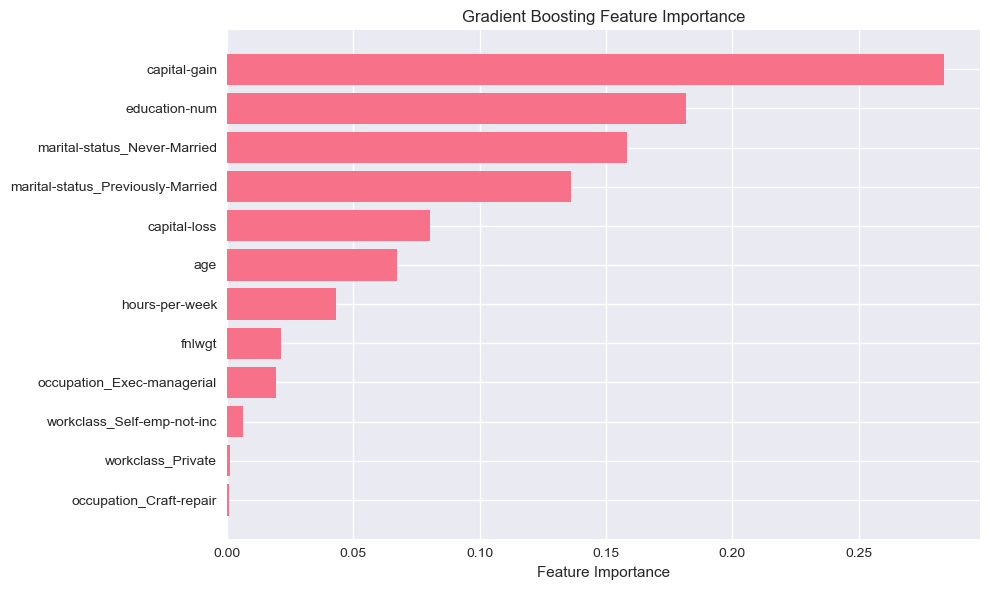

In [157]:
# ============================================================================
# GRADIENT BOOSTING: BEST FIT & FEATURE IMPORTANCE
# ============================================================================
# Use the best gradient boosting model
best_gb = GradientBoostingClassifier(
 n_estimators=500, 
 max_depth=3,
 learning_rate=0.1,
 random_state=42
)

start_time = time.time()
best_gb.fit(X_train_selected, y_train)
gb_train_score = best_gb.score(X_train_selected, y_train)
gb_test_score = best_gb.score(X_test_selected, y_test)
end_time = time.time()

# Best Results
print("\n" + "=" * 60)
print("MODEL 8: Gradient Boosting")
print("=" * 60)
print(f"Final Model fitting complete.")
print(f"• Final Training Accuracy: {gb_train_score:.4f}")
print(f"• Final Test Accuracy: {gb_test_score:.4f}")
print(f"- Training Time: {end_time - start_time:.4f} seconds")

# --------------------------------------------
# GB's FEATURE IMPORTANCE
# --------------------------------------------
feature_importance = best_gb.feature_importances_

print("\n" + "=" * 60)
print("GRADIENT BOOSTING FEATURE IMPORTANCE")
print("=" * 60)

print(f"Feature Importance Ranking:")
gb_importance_df = pd.DataFrame({
 'Feature': feature_names,
 'Importance': feature_importance
}).sort_values('Importance', ascending=False)

for i, row in gb_importance_df.iterrows():
 print(f"{row.name+1:2d}. {row['Feature']:15} {row['Importance']:.4f}")
    
# Plot feature importance
print(f"\nMost important feature: {gb_importance_df.iloc[0]['Feature']}")

plt.figure(figsize=(10, 6))
plt.barh(range(len(gb_importance_df)), gb_importance_df['Importance'])
plt.yticks(range(len(gb_importance_df)), gb_importance_df['Feature'])
plt.xlabel('Feature Importance')
plt.title('Gradient Boosting Feature Importance')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

##### Detailed explanation (5-6 sentences):
While AdaBoosting minimizes error by increasing the weight of the misclassified data points for every iteration, Gradient Boosting minimizes a loss function by iteratively fitting new learners to the residuals of the previous ensemble. By doing this, it builds the next tree to predict the error of the previous tree so that it won't make the same mistake. The model keeps doing this until the residuals are near zero. Gradient Boosting can outperform AdaBoosting because it generalizes the error to the whole model rather than focusing on specific data points. AdaBoosting's flaw makes it prone to overfitting or bias, hence Gradient Boosting is a more flexible and robust model than AdaBoosting.

In [206]:
# ----------------------------
# TRAINING SUMMARY TABLE
# ----------------------------

model_summary_dict = {
    "Model Name": [
        "Decision Tree", 
        "Random Forest", 
        "AdaBoost", 
        "Gradient Boosting"
    ],
    "Training Accuracy": [
        0.9998, 
        0.8625, 
        0.8484, 
        0.8724
    ],
    "Ensemble Type": [
        "None", 
        "Bagging", 
        "Boosting", 
        "Boosting"
    ],
    "Number of Estimators": [
        "N/A", 
        500, 
        200, 
        500
    ],
    "Learning Approach": [
        "Single Path", 
        "Parallel", 
        "Sequential", 
        "Sequential"
    ],
    "Key Characteristics/Notes": [
        "Highest training accuracy but likely overfit.",
        "Reduces variance via feature randomness.",
        "Fixes misclassified points via re-weighting.",
        "Optimizes residuals via gradient descent at a 0.1 rate."
    ]
}

# Display summary table
summary_df = pd.DataFrame(model_summary_dict)

print("="*50)
print("TRAINING SUMMARY TABLE FOR ENSEMBLE METHODS")
print("="*50)
display(summary_df)

TRAINING SUMMARY TABLE FOR ENSEMBLE METHODS


,Model Name,Training Accuracy,Ensemble Type,Number of Estimators,Learning Approach,Key Characteristics/Notes
0,Decision Tree,0.9998,None,N/A,Single Path,Highest training accuracy but likely overfit.
1,Random Forest,0.8625,Bagging,500,Parallel,Reduces variance via feature randomness.
2,AdaBoost,0.8484,Boosting,200,Sequential,Fixes misclassified points via re-weighting.
3,Gradient Boosting,0.8724,Boosting,500,Sequential,Optimizes residuals via gradient descent at a ...


## 4. Ensemble Feature Importance Analysis

### 4A. Feature Importance Comparison

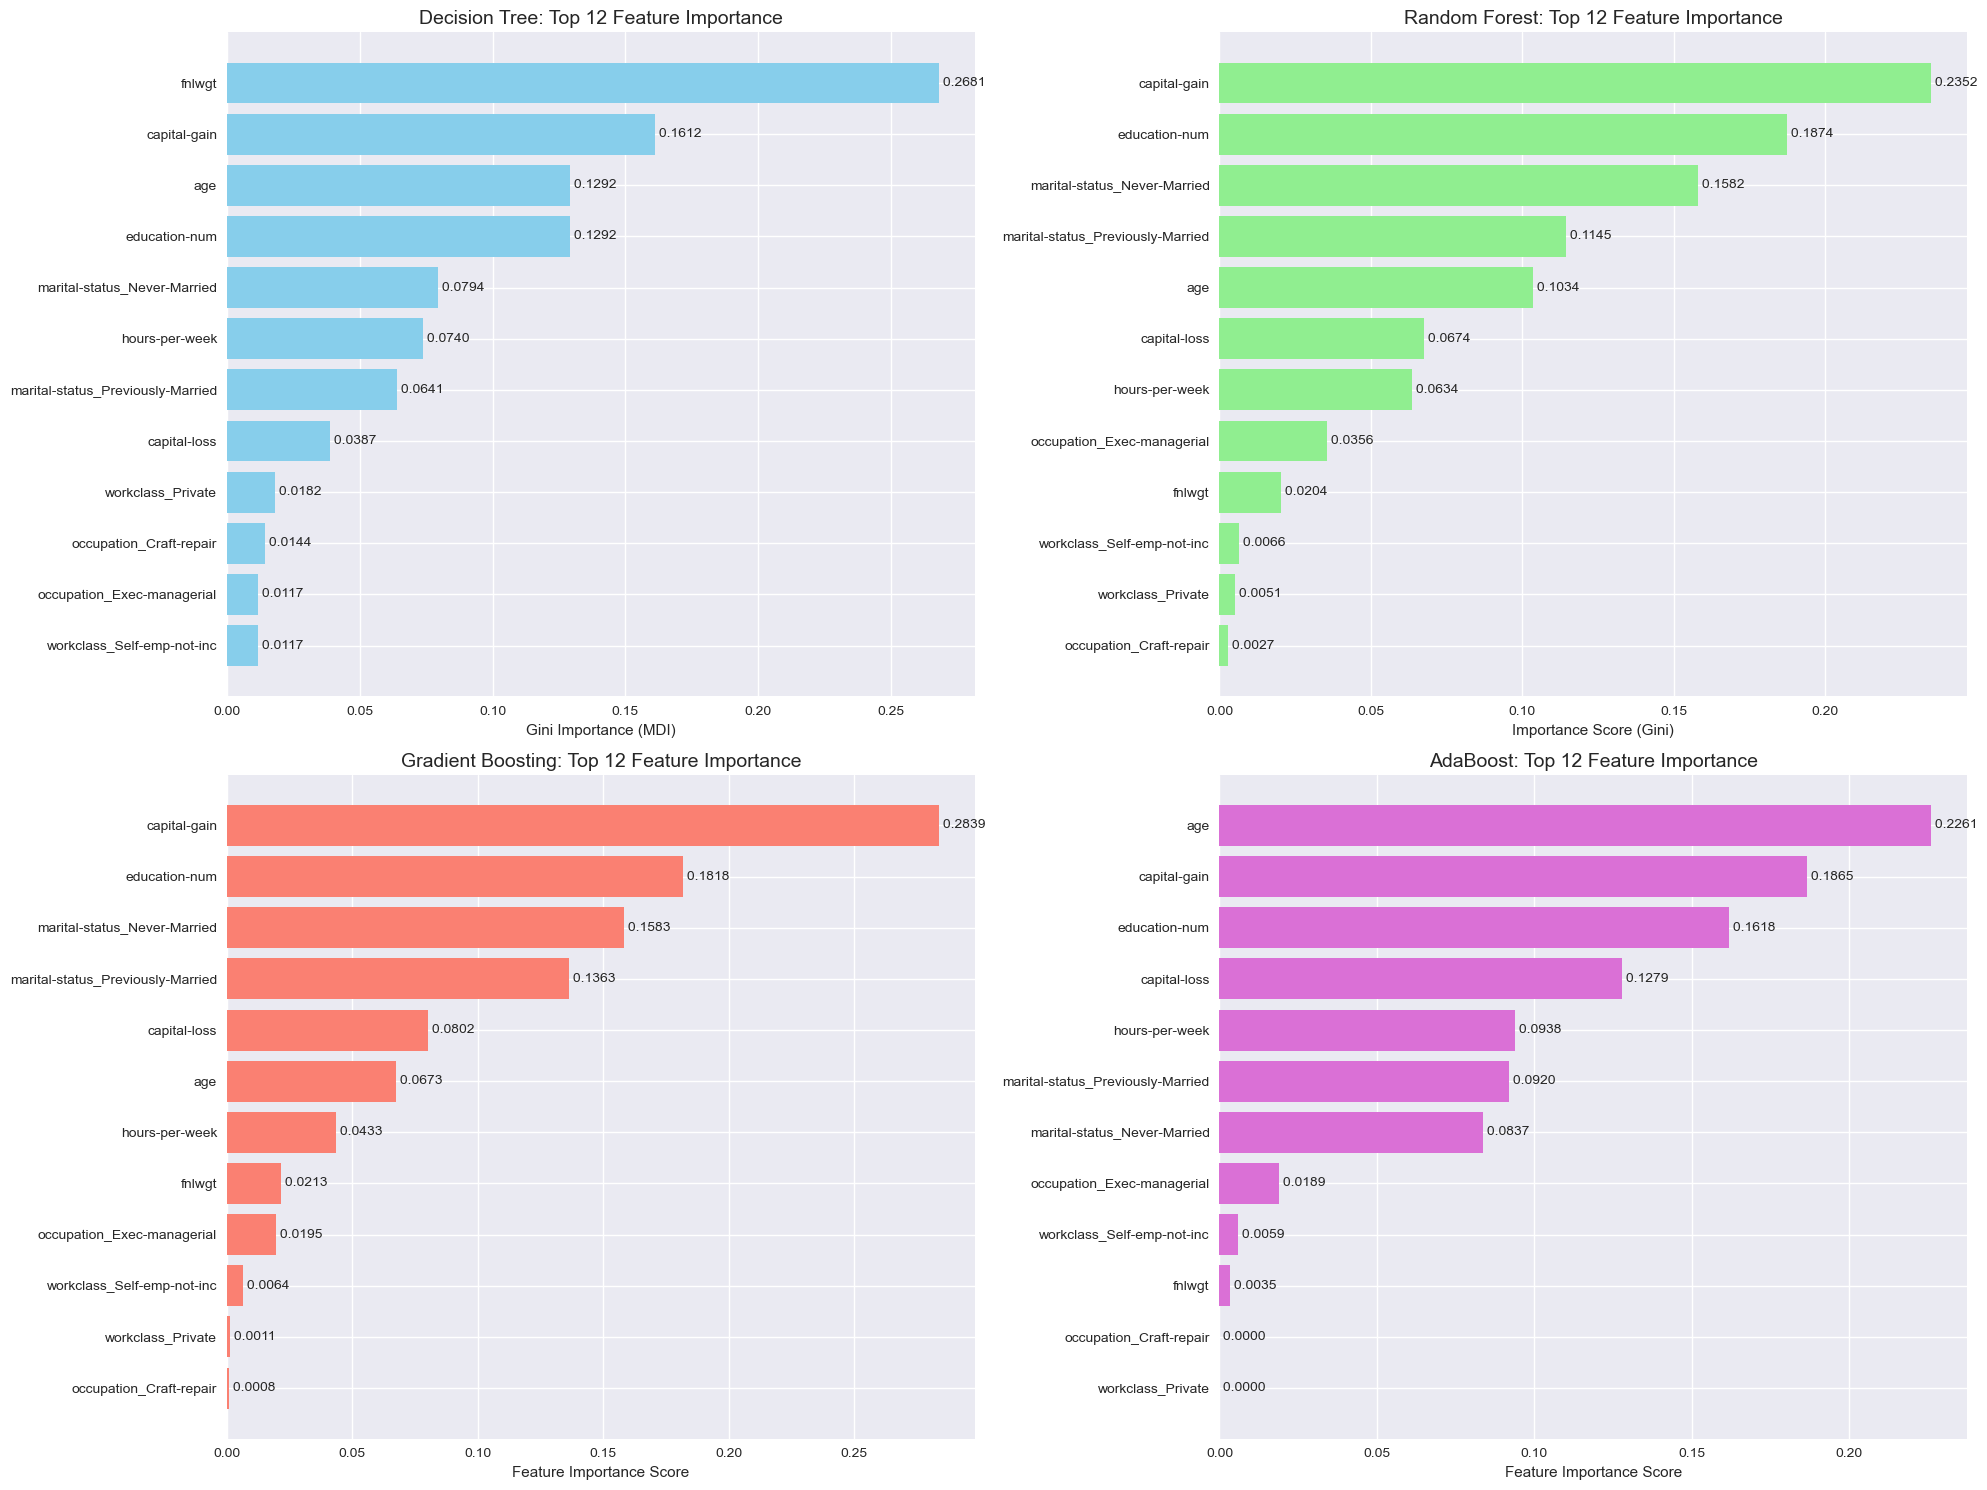

TOP 3: FEATURE IMPORTANCES


,Decision Tree,Random Forest,AdaBoost,Gradient Boosting
Rank 1,fnlwgt,capital-gain,age,capital-gain
Rank 2,capital-gain,education-num,capital-gain,education-num
Rank 3,age,maritalstatus-NeverMarried,education-num,maritalstatus-NeverMarried


In [221]:
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(20, 15))

# --- 1. Decision Tree ---
dt_plot_df = dt_importance_df.sort_values(by='Importance', ascending=True).tail(12)
ax1.barh(dt_plot_df['Feature'], dt_plot_df['Importance'], color='skyblue')
ax1.set_title('Decision Tree: Top 12 Feature Importance', fontsize=14)
ax1.set_xlabel('Gini Importance (MDI)')
for index, value in enumerate(dt_plot_df['Importance']):
    ax1.text(value, index, f' {value:.4f}', va='center')

# --- 2. Random Forest ---
rf_plot_df = best_rf_importance_df.sort_values(by='Importance', ascending=True).tail(12)
ax2.barh(rf_plot_df['Feature'], rf_plot_df['Importance'], color='lightgreen')
ax2.set_title('Random Forest: Top 12 Feature Importance', fontsize=14)
ax2.set_xlabel('Importance Score (Gini)')
for index, value in enumerate(rf_plot_df['Importance']):
    ax2.text(value, index, f' {value:.4f}', va='center')

# --- 3. Gradient Boosting ---
gb_plot_df = gb_importance_df.sort_values(by='Importance', ascending=True).tail(12)
ax3.barh(gb_plot_df['Feature'], gb_plot_df['Importance'], color='salmon')
ax3.set_title('Gradient Boosting: Top 12 Feature Importance', fontsize=14)
ax3.set_xlabel('Feature Importance Score')
for index, value in enumerate(gb_plot_df['Importance']):
    ax3.text(value, index, f' {value:.4f}', va='center')

# --- 4. AdaBoost ---
ada_plot_df = ada_feature_importance_df.sort_values(by='Importance', ascending=True).tail(12)
ax4.barh(ada_plot_df['Feature'], ada_plot_df['Importance'], color='orchid')
ax4.set_title('AdaBoost: Top 12 Feature Importance', fontsize=14)
ax4.set_xlabel('Feature Importance Score')
for index, value in enumerate(ada_plot_df['Importance']):
    ax4.text(value, index, f' {value:.4f}', va='center')

plt.tight_layout()
plt.show()

# --------------------------------
# COMPARISON TABLE
# --------------------------------

top3_features = {
    'Decision Tree': ['fnlwgt', 'capital-gain', 'age'],
    'Random Forest': ['capital-gain', 'education-num', 'maritalstatus-NeverMarried'],
    'AdaBoost': ['age', 'capital-gain', 'education-num'],
    'Gradient Boosting': ['capital-gain', 'education-num', 'maritalstatus-NeverMarried']
}

top3_features_df = pd.DataFrame(top3_features, index=['Rank 1', 'Rank 2', 'Rank 3'])

print("="*60)
print("TOP 3: FEATURE IMPORTANCES")
print("="*60)
display (top3_features_df)

##### Interpretation
Given the dataframe, we can easily see how capital-gain remains in the Top 3 ranking of the feature importances regardless of which ensemble method is used. The three features in the Random Forest, AdaBoost, and Gradient Boosting models are actually all the same, just with varying weights to their own respective models. Since these three models agree with each other, this provides a higher confidence that these features are really the primary predictors in this dataset.

### 4B. Feature Stability Analysis

##### Ensemble Vs. Single Decision Trees
The ensemble model's feature importance ranking is more reliable than single decision trees because it can properly utilize the whole data, making it well-represented and not sensitive to potential noise within the dataset. It uses feature randomness, so that the other features are not outshined by the strong predictors. With this, the model (Random Forest & Gradient Boosting) provides a more balanced result that does not lead to overfitting, unlike Decision trees.

##### Boosting vs. Bagging Feature Analysis

Comparing Boosting and Bagging's features, there is little to no difference as they both derive predicting power from the same features, just with varying weights depending on the model. If ever they might differ, it is because they process these features differently. Bagging methods looks for the feature that is consistently useful among the many subsets of data, while Boosting looks for the feature that is efficient in minimizing the error.

## 5. Model Performance Evaluation

### 5A. Test Predictions & Confusion Matrices

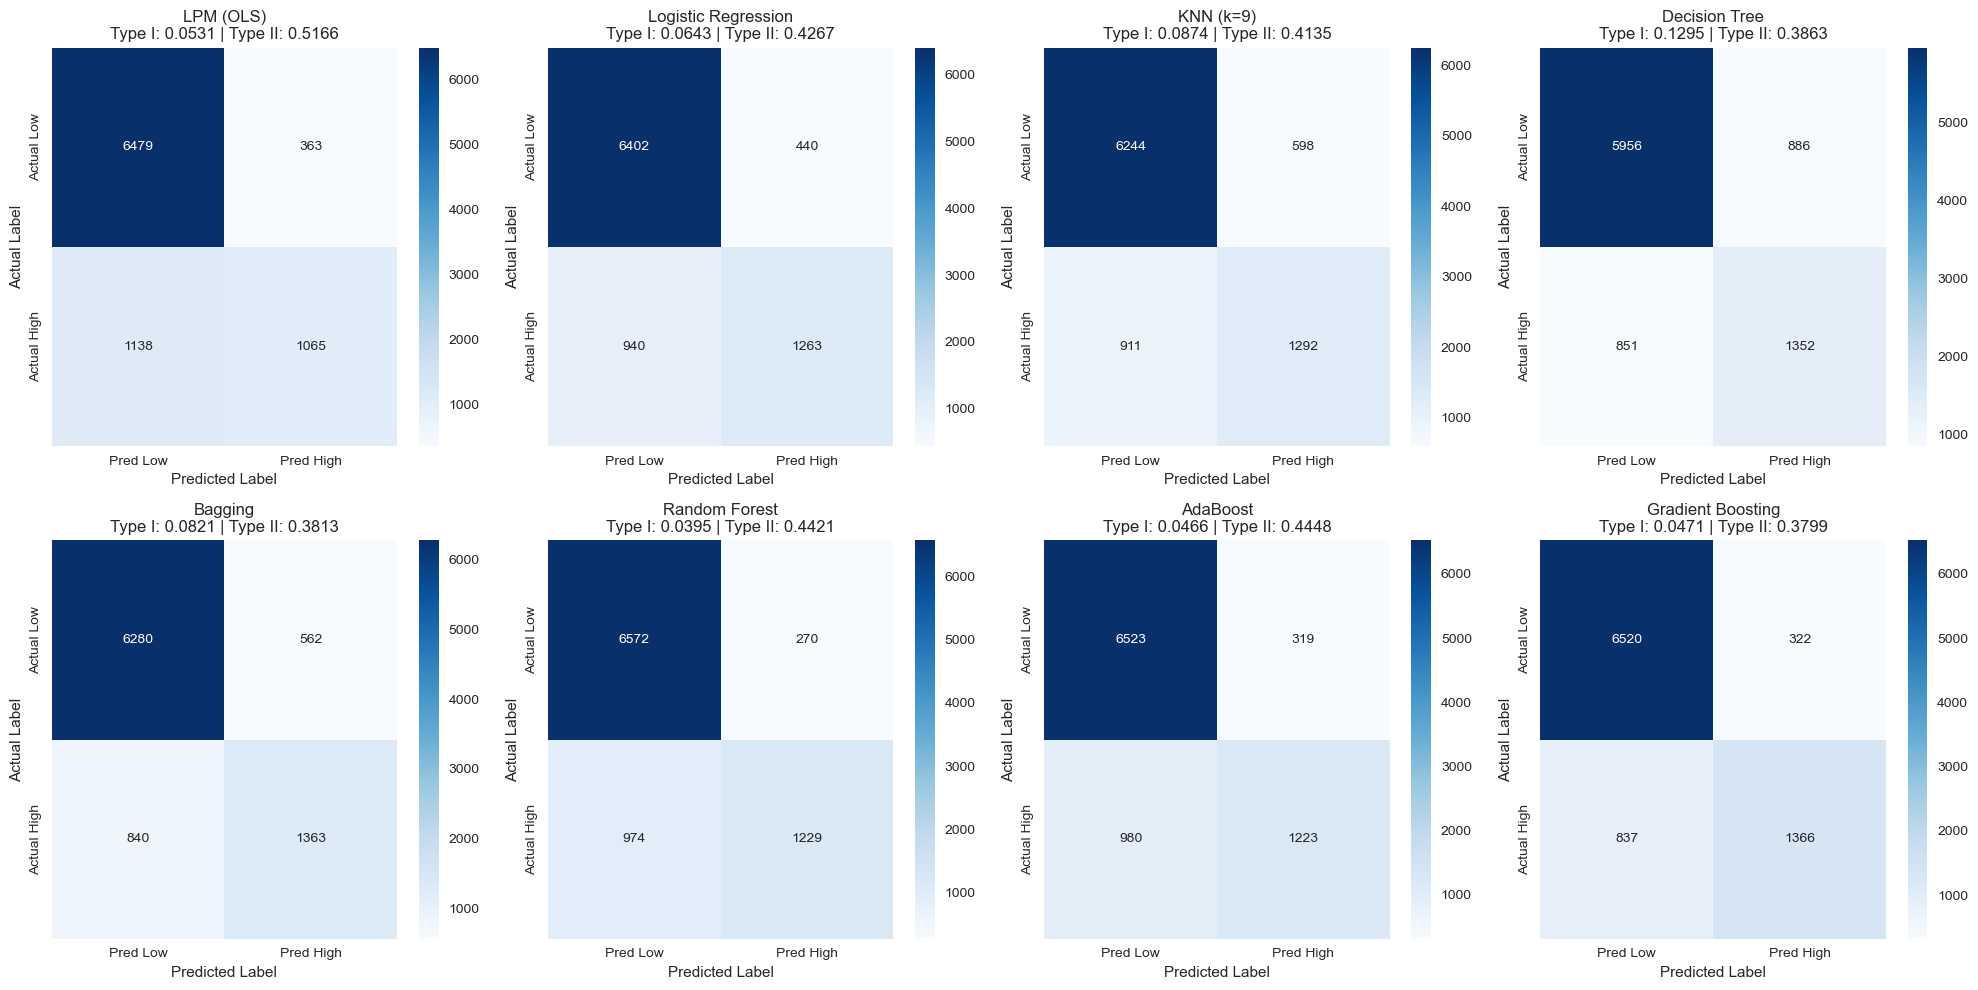

In [167]:
models = {
    "LPM (OLS)": (lpm_model, X_test_selected),
    "Logistic Regression": (logit_model, X_test_selected),
    "KNN (k=9)": (final_knn, X_test_scaled),
    "Decision Tree": (final_dt, X_test_selected),
    "Bagging": (bagging_model, X_test_selected),
    "Random Forest": (best_rf, X_test_selected),
    "AdaBoost": (ada_model, X_test_selected),
    "Gradient Boosting": (best_gb, X_test_selected)
}

# Adjusted figure size for 8 models
plt.figure(figsize=(20, 10))

for i, (name, (model, X_test_data)) in enumerate(models.items(), 1):
    
    # --- 1. PREDICTION LOGIC ---
    if "LPM" in name or "Logistic" in name:
        if X_test_data.shape[1] == 12:
            X_test_data_fixed = sm.add_constant(X_test_data, has_constant='add')
        else:
            X_test_data_fixed = X_test_data
            
        y_probs = model.predict(X_test_data_fixed)
        y_pred = (y_probs >= 0.5).astype(int)
    else:
        y_pred = model.predict(X_test_data)
    
    # --- 2. CONFUSION MATRIX ---
    cm = confusion_matrix(y_test, y_pred)
    
    # Handling cases where the matrix might not be 2x2
    if cm.size == 4:
        tn, fp, fn, tp = cm.ravel()
    else:
        # Fallback for single-class predictions
        tn = cm[0,0] if cm.size > 0 else 0
        fp = fn = tp = 0
    
    type_i_error = fp / (fp + tn + 1e-9)
    type_ii_error = fn / (fn + tp + 1e-9)
    
    # --- 3. VISUALIZATION ---
    # Changed to 2 rows and 4 columns to fit all 8 models
    plt.subplot(2, 4, i)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=['Pred Low', 'Pred High'],
                yticklabels=['Actual Low', 'Actual High'])
    
    plt.title(f"{name}\nType I: {type_i_error:.4f} | Type II: {type_ii_error:.4f}")
    plt.ylabel('Actual Label')
    plt.xlabel('Predicted Label')

plt.tight_layout()
plt.show()

##### Confusion Matrix and Error Analysis
* **Which model has the highest Type 1 Error (False Positives) rate?**  
Decision Tree is the model most prone to making Type I errors among the models (Type I Error Rate = 0.1295) due to their greedy nature to reduce its Gini Impurity for every branch of the tree.

* **Which model has the lowest Type 1 Error rate?**    
Random Forest has the lowest Type 1 error rate of 0.0395, next to Gradient Boosting with an error rate of 0.0471. Random Forest produces the least False Positives due to its resistant to noisy neighbors/data points as it follows majority voting, while Gradient Boosting creates a cautious model due to its distinct learning rates only leading towards the right classification through incremental steps.

* **Which model has the highest Type 2 Error (False Negatives) rate?**  
Linear Probability Model is the model most prone to making Type II errors among the models. This makes sense as this model is usually conservative or cautious when it comes to predicting outcomes of 1 because the model is looking for the linearity of the dataset that may be rare in social datasets similar to Adult Income.

* **Which model has the lowest Type 2 Error rate?**    
Gradient Boosting has the lowest Type 2 error rate of 0.3799, next to Bagging with an error rate of 0.3813. Gradient Boosting has the lowest Type 2 error due to its method that learns from its mistakes continuously, while Bagging uses bootstrapping to create diverse subsets that makes real positives hard to miss.

* **How do boosting methods (AdaBoost, Gradient Boosting) compare to Random Forest in terms of both error types?**   
Random Forest has a lower Type I error rate than both boosting methods, while Gradient Boosting has lower Type II error than Random Forest. This means that boosting methods are more prone to making False Positives than Random Forest. On the other hand, Gradient Boosting has a lower Type II error rate because of its utilization of the loss function. The better choice between the two models will differ on its application in real-life.

### 5B. Classification Metrics Comparison

In [169]:
eval_sets = {
    "Train": (X_train_selected, X_train_scaled, y_train),
    "Test": (X_test_selected, X_test_scaled, y_test)
}

performance_data = []

for set_name, (X_raw, X_scaled, y_true) in eval_sets.items():
    
    # Inner loop for each model
    for model_name, (model, is_scaled) in {
        "LPM (OLS)": (lpm_model, False),
        "Logistic": (logit_model, False),
        "KNN": (final_knn, True),
        "Decision Tree": (final_dt, False),
        "Bagging": (bagging_model, False),
        "Random Forest": (best_rf, False),
        "AdaBoost": (ada_model, False),      # Added AdaBoost
        "Gradient Boosting": (best_gb, False) # Added Gradient Boosting
    }.items():
        
        # Select appropriate data
        data = X_scaled if is_scaled else X_raw
        
        # --- 1. GENERATE BINARY PREDICTIONS ---
        if "LPM" in model_name or "Logistic" in model_name:
            if data.shape[1] == 12:
                data_with_const = sm.add_constant(data, has_constant='add')
            else:
                data_with_const = data
                
            y_probs = model.predict(data_with_const)
            y_pred = (y_probs >= 0.5).astype(int)
        else:
            y_pred = model.predict(data)
        
        # --- 2. CALCULATE METRICS ---
        performance_data.append({
            "Dataset": set_name,
            "Model": model_name,
            "Accuracy": accuracy_score(y_true, y_pred),
            "F1-Score": f1_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred),
            "Recall": recall_score(y_true, y_pred)
        })

# --- 3. Create DataFrame and Sort ---
comparison_df = pd.DataFrame(performance_data)
# Sorting by Model then Dataset (Train then Test) for side-by-side comparison
comparison_df = comparison_df.sort_values(by=['Model', 'Dataset'], ascending=[True, False])

print("\n" + "=" * 80)
print("TRAINING VS. TESTING PERFORMANCE COMPARISON")
print("=" * 80)
print(comparison_df.round(4).to_string(index=False))


TRAINING VS. TESTING PERFORMANCE COMPARISON
Dataset             Model  Accuracy  F1-Score  Precision  Recall
  Train          AdaBoost    0.8484    0.6460     0.7712  0.5558
   Test          AdaBoost    0.8564    0.6531     0.7931  0.5552
  Train           Bagging    0.9998    0.9996     0.9997  0.9994
   Test           Bagging    0.8450    0.6604     0.7081  0.6187
  Train     Decision Tree    0.9998    0.9996     1.0000  0.9991
   Test     Decision Tree    0.8080    0.6089     0.6041  0.6137
  Train Gradient Boosting    0.8724    0.7152     0.8045  0.6438
   Test Gradient Boosting    0.8719    0.7021     0.8092  0.6201
  Train               KNN    0.8755    0.7327     0.7866  0.6857
   Test               KNN    0.8332    0.6313     0.6836  0.5865
  Train         LPM (OLS)    0.8292    0.5855     0.7392  0.4847
   Test         LPM (OLS)    0.8341    0.5866     0.7458  0.4834
  Train          Logistic    0.8396    0.6397     0.7258  0.5719
   Test          Logistic    0.8474    0.6467

##### Analysis

* **Which model achieves the highest accuracy?**  
Gradient Boosting achieved the highest accuracy of 87.19%. It is noticeable that there is a very small difference between the train and test accuracy, only dropping by 0.05%. While both AdaBoost and Gradient Boosting utilize ensemble boosting techniques, the integration of a learning rate in the latter proved important in optimizing the model's performance.

* **Which model has the best balance between precision and recall?**  
The best balance between precision and recall describes the F1-Score. Among the models, the Gradient Boosting model showed a better balance/trade-off between precision and recall (F1-Score = 0.7021).

##### Performance Ranking & Analysis

**Ranking by Accuracy:**  
1. Gradient Boosting: 0.8719
2. Random Forest: 0.8625
3. AdaBoost: 0.8564
4. Logistic Regression: 0.8474
5. Bagging: 0.8450

**Ranking by F1-Score:**
1. Gradient Boosting: 0.7021
2. Random Forest: 0.6640
3. Bagging: 0.6604
4. AdaBoost: 0.6531
5. Logistic Regression: 0.6467

**Error Rate Rankings:** (Calculated by averaging the FP and FN)
1. Gradient Boosting - 0.1281
2. Random Forest - 0.1375
3. AdaBoost - 0.1436
4. Logistic Regression - 0.1526
5. Bagging - 0.1550

* **Which model achieves the best overall performance?**     
Gradient Boosting achieves the best overall performance. It holds the 1st place in both Accuracy and F1-score. Although it has a moderate Recall score of 62.01% and high Precision score of 80.92%, which means that the model remains conservative and cautious in predicting the outcomes, the model still has the best balance between the two among the other models.

* **Are there significant differences between the rankings?**    
The ranking is almost the exact same for accuracy and F1-score rankings, except for AdaBoost, Bagging, and Logistic Regression switching places on the bottom third. Specifically, while Bagging ranks lower in overall Accuracy, its rise in the F1-score ranking suggests it is slightly more effective at balancing Type I (False Positives) and Type II (False Negatives) errors compared to the other models.


* **Do boosting methods show better error reduction than bagging?**    
According to the error rankings, boosting methods show a better placement than bagging methods. Although Random Forest ranked second place, bagging achieved a worse error rate than both boosting methods listed. 

* **Which approach handles the class imbalance better?**   
Gradient Boosting is typically the strongest choice for imbalanced data because of how it learns. It eventually "learns" the rare patterns of the High Income group, which it has a lower Type II error.

##### AdaBoost vs. Gradient Boosting Comparison
Among all metrics, Gradient Boosting did a better job in predicting the right outcomes and minimizing errors. Their Type I error rates are mostly the same, but Gradient Boosting has a lower Type II error rate than AdaBoost. The Gradient Boosting does a better job in minimizing these False Negatives because it focuses on the residuals of the entire model, not just specific misclassified data points. By increasing the weights of these data points in AdaBoost, it might lead to high variancy creating more False Negatives. Overall, I would recommended Gradient Boosting as it is more robust and generalizing than AdaBoost.

## 6. Model Recommendation and Insights

### 6A. Model Selection and Justification

After the comparing different kinds of models for the Adult Income dataset to predict those individuals with high income or not, the current best model is **Gradient Boosting** with an accuracy of 87.19% and F1-score of 70.21%. Gradient Boosting earns the top spot for the accuracy and F1-scores ranking, as it is the model that produces the least Type I and II errors together. The model only produced 322 false positives and 837 false negatives, which means that its total error rate is 12.81% only.

**Error Rate Rankings:** (Calculated by averaging the FP and FN)
1. Gradient Boosting - 0.1281
2. Random Forest - 0.1375
3. AdaBoost - 0.1436
4. Logistic Regression - 0.1526
5. Bagging - 0.1550

If not Gradient Boosting, the alternative best fit model would be **Random Forest**. Given its F1-Score of 66.04%, it is the second most balanced model when it comes to balancing errors in its predictions.

### 6B. Trade-offs and Practical Considerations

In choosing the model best for the dataset, we always look for the best F1-score and least Type I and II error rates. In all rankings for accuracy, F1-score, and least error rates, Gradient Boosting earns the top spot making it the most suitable model for the dataset.

For a dataset like the Adult Income, both Type I and II errors can actually penalize the model. In the context of a bank, the bank is evaluating its customers to know which ones can receive credit cards or not. Typically, only those with the ability to pay back the debt are the ones receiving these kinds of offers from banks.

With a Type I Error (False Positive), if a bank gives out these credit cards to those who are not able to pay back their own credit given they do not actually have high income, it will be a costly mistake to the bank as it is a waste of marketing budget and misallocation of resources.

With a Type II Error (False Negatives), if a bank does not give out these credit cards to those who are actually have high income, they are missing out on opportunities, like customers, financial sponsors, and more. Even though they are not directly losing money, they are missing out on the potential money.

Hence, the best model should have a perfect balance of Precision and Recall to reduce these errors as much as possible, which is Gradient Boosting.

In terms of interpretabililty, Gradient Boosting is a black box model that cannot be interpreted. In real-life applications, being able to interpret the underlying logic of the data is essential. So instead of coefficients, we can utilize feature importances for interpretations. Feature importances allows us to understand the importance of each features/variables and show us which has the most impact to the model's predicting power.

### 6C. Key Insights and Learning Outcomes

For this study, I learned the advantage of ensemble methods, specifically Gradient Boosting. With how ensemble methods produce and trains the data in subsets, Gradient Boosting achieves a smarter and more efficient model by learning from its mistakes for every iteration and utilizing its learning rate to regulate and prevent overfitting. Through this, the model's predictive power becomes more powerful as it creates the least possible errors in the output. It's a simple concept that we always apply in real-life, but it exists as an innovative method in the field of data science and machine learning. 